# Które modele AW26 potrzebują pomocy, zanim skończy się pełna cena? Sell-through i decyzja o wcześniejszej przecenie

## Metadata & Purpose

| | |
|---|---|
| **Autor** | agent AI (materiał szkoleniowy; dane syntetyczne) |
| **Data wykonania** | 2026-11-10; stan danych i „dzisiaj" w analizie: **2026-09-20** |
| **Zespół** | Data Science, na zlecenie merchandisingu i działu cen i promocji sieci Nordvik |
| **Status** | notebook w budowie: zawiera fazy 1–3 (zrozumienie zlecenia, audyt danych, eksploracja). Kolejne sekcje (hipotezy i walidacja, baseline'y, modele, kalibracja, wynik dla biznesu, dziennik, post-mortem) są dopisywane w następnych etapach |

### Kontekst i zlecenie (własnymi słowami)

Nordvik to polska sieć odzieżowa (5 sklepów stacjonarnych i sklep internetowy). Asortyment sezonowy sprzedaje się w dwóch sezonach: `SS` (luty–lipiec) i `AW` (sierpień–styczeń), a **model** (kod `StyleCode`, np. jedna konkretna sukienka we wszystkich kolorach i rozmiarach) wchodzi do sprzedaży w jednej z kilku „transz" premierowych. Cykl ceny modelu wygląda zwykle tak: **pełna cena** do ok. 8. tygodnia od premiery, potem **rabat sezonowy** (−20…−30%, 2–3 tygodnie), potem **wyprzedaż** (−40…−60%) do końca sezonu. Decyzję o rabacie dział cen podejmuje dla każdego modelu osobno.

Kolekcja **AW26** (jesień–zima 2026) weszła do sprzedaży w trzech transzach: 3, 17 i 31 sierpnia 2026. Zleceniodawca pyta (parafraza):

> Jesteśmy ok. 7 tygodni po starcie kolekcji. Dziś decydujemy o rabacie „na czuja", na podstawie raportu sprzedaży i stanów. Które modele **nie osiągną „zdrowego" sell-through do końca okresu pełnej ceny** (ok. 8 tygodni od premiery) i którym warto pomóc wcześniej: przesunięciem zapasu między sklepami, lepszą ekspozycją albo wcześniejszą przeceną? Roboczo „zdrowy" to 60% w 8. tygodniu, ale to do dyskusji. Przecena zbyt wcześnie zabiera marżę, zbyt późno zamraża zapas i wymusza głębszą wyprzedaż. Kosztów dokładnie nie policzyliśmy.

**Sell-through** (wskaźnik wyprzedania) to udział sprzedanych sztuk w całości, którą firma miała do sprzedania: sztuki sprzedane / (sztuki sprzedane + stan magazynowy na koniec okresu). Sell-through 60% oznacza, że z każdych 100 sztuk modelu 60 już sprzedano, a 40 leży w magazynach i sklepach.

### Cel analizy

1. Ustalić, **co faktycznie można policzyć** (ile zakończonych kolekcji i modeli mamy, jak dobre są stany, co wiemy o dostawach i przecenach).
2. Zbudować i porównać metody oceny ryzyka niedoboru sell-through dla modelu w każdym tygodniu od premiery, od prostych reguł po modele statystyczne, z uczciwą walidacją i niepewnością.
3. Przełożyć wynik na decyzję: lista modeli AW26 z oceną ryzyka i proponowanym działaniem, reguła „kiedy flagować" i jej oczekiwany koszt wobec obecnej praktyki.

### Hipotezy robocze (formalne progi i miary zapiszę przed testami, w fazie 4)

- **H1 (wczesne tempo):** tempo sprzedaży w tygodniach 1–3 jest silnym predyktorem sell-through w 8. tygodniu, ale zawodzi dla modeli o szybkim starcie i szybkim wygasaniu.
- **H2 (ekstrapolacja liniowa i sezonowość):** liniowa ekstrapolacja tempa jest obciążona dla kategorii sezonowych (zaniża wynik, gdy sezon dopiero nabiera tempa). Uwaga z góry: dla sezonu `AW` mam co najwyżej jedną zakończoną kolekcję, więc ten wniosek będzie z natury słabo ugruntowany.
- **H3 (złożoność modelu):** przy tej liczbie modeli model gradientowy nie pokona prostej regresji z kilkoma cechami (Brier score, log loss, walidacja po kolekcjach).
- **H4 (rozmiary):** wczesne wyczerpanie zapasu w rozmiarach M i L ogranicza późniejszą sprzedaż modelu poniżej poziomu wynikającego z tempa, więc cecha dostępności rozmiarów poprawia predykcję.

### Wyniki

Uzupełniane na końcu pracy (sekcja Results & Conclusions). Do tego miejsca notebook jest zapisem toku pracy.

### Jak czytać ten notebook

Każdy krok ma trzy elementy: **po co** to robię (przed kodem), **co widzę** (po wyniku, tylko fakty) i **wniosek / decyzja** (interpretacja, oznaczona jako moja). Założenia i niepewności są oznaczone słowami **ZAŁOŻENIE** i **NIEPEWNOŚĆ**. Ślepe uliczki i zmiany zdania zostają w notebooku.

## Setup

**Po co:** wersje bibliotek, ziarno losowe i ścieżki w jednym miejscu, żeby dało się odtworzyć wynik. Ścieżkę do danych można podać zmienną środowiskową `NORDVIK_BC04_DATA`; żadnych haseł ani adresów usług w tej analizie nie używam.

In [1]:
import os
import sys
import warnings
from pathlib import Path

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 20260920  # data odcięcia, jedno ziarno dla całego notebooka
rng = np.random.default_rng(SEED)

DATA = Path(os.getenv("NORDVIK_BC04_DATA", "../../datasets/synthetic/bc04")).resolve()
CACHE = Path("cache")
CACHE.mkdir(exist_ok=True)

AS_OF = pd.Timestamp("2026-09-20")  # punkt odcięcia danych = „dzisiaj" w tej analizie

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 100, "axes.titlesize": 12, "axes.labelsize": 10})

print("Python", sys.version.split()[0])
for m in (pd, np, scipy, duckdb, matplotlib, sns):
    print(f"{m.__name__:12s} {m.__version__}")
print("Katalog danych:", DATA.name, "| istnieje:", DATA.exists())

Python 3.12.3
pandas       2.3.3
numpy        2.5.4
scipy        1.18.1
duckdb       2.0.0
matplotlib   3.11.2
seaborn      0.13.2
Katalog danych: bc04 | istnieje: True


## Load Data

**Po co:** wczytuję sześć tabel (opis niżej). Duże tabele faktów (ok. 0,5 mln wierszy sprzedaży i 0,65 mln migawek stanów) zostawiam w DuckDB jako widoki nad plikami Parquet i agreguję zapytaniami SQL, a małe wymiary wczytuję do pandas.

**Opis danych** (źródło: wyciąg z hurtowni Nordvik i jednorazowy eksport stanów magazynowych):

| Tabela | Ziarno (jeden wiersz to…) | Najważniejsze kolumny |
|---|---|---|
| `dim_date` | dzień | `Date`, `IsoYear`, `IsoWeek`, `Season` (np. `AW26`; styczeń należy do AW poprzedniego roku) |
| `dim_store` | sklep lub kanał online | `StoreKey`, `StoreName`, `Channel` (`STORE`/`ONLINE`) |
| `dim_product` | SKU = model × kolor × rozmiar | `ProductKey`, `StyleCode` (model), `Category`, `Color`, `Size` (XS–XL, akcesoria `ONE`), `ListPrice` (brutto), `UnitCost` (koszt netto) |
| `merch_plan` | model | `Collection` (`SS25`, `AW25`, `SS26`, `AW26`), `LaunchDate` (**planowana** data wejścia), `PlannedUnits` (plan zakupu dla całej sieci, nie faktyczna dostawa) |
| `fact_sales` | pozycja paragonu lub zamówienia | `DateKey`, `ProductKey`, `StoreKey`, `Quantity`, `UnitPrice` (cena przed rabatem, brutto), `DiscountAmount`, `GrossAmount`, `NetAmount`, `UnitCost` |
| `fact_inventory_daily` | dzień × SKU × lokalizacja | `StockQuantity`: **migawka** stanu na koniec dnia |

**Ograniczenia, które mają znaczenie dla całej analizy** (z opisu danych):
- Dane obejmują tylko modele sezonowe czterech kolekcji: trzy zakończone (`SS25`, `AW25`, `SS26`) i jedną w toku (`AW26`).
- **Stany historyczne to jednorazowy eksport** o nieznanej jakości. Normalnie hurtownia trzyma stany tylko dla bieżącego sezonu, więc przed użyciem trzeba je sprawdzić (faza 2).
- **Brak tabeli dostaw i przesunięć** między lokalizacjami: widać tylko stan wynikowy. Brak historii cennika: rabat widać wyłącznie w `DiscountAmount`.
- Stan jest migawką: stanów z kolejnych dni nie sumuję, a różnica dwóch migawek nie jest sprzedażą.
- `PlannedUnits` to plan, `LaunchDate` to data planowana: faktyczny start sprzedaży może się różnić.
- Brak zwrotów, identyfikatora klienta i ruchu w sklepach.

Definicje metryk (sztuki, sprzedaż netto, stan, dostępność, sell-through, wartość zapasu, tydzień handlowy) pochodzą ze słownika metryk Nordvik; przytaczam je w miejscach użycia. Tydzień handlowy to pełny tydzień ISO, a do grupowania tygodni używam pary `IsoYear` + `IsoWeek` (nigdy `Year` + `IsoWeek`).

In [2]:
con = duckdb.connect()  # baza w pamięci; widoki wskazują na pliki Parquet
for t in ["dim_date", "dim_store", "dim_product", "merch_plan", "fact_sales", "fact_inventory_daily"]:
    con.execute(f"CREATE OR REPLACE VIEW {t} AS SELECT * FROM read_parquet('{(DATA / (t + '.parquet')).as_posix()}')")

dim_date = con.sql("SELECT * FROM dim_date").df()
dim_store = con.sql("SELECT * FROM dim_store").df()
dim_product = con.sql("SELECT * FROM dim_product").df()
merch_plan = con.sql("SELECT * FROM merch_plan").df()

for name, df in [("dim_date", dim_date), ("dim_store", dim_store), ("dim_product", dim_product), ("merch_plan", merch_plan)]:
    print(f"{name}: {df.shape[0]} wierszy x {df.shape[1]} kolumn")
for t in ["fact_sales", "fact_inventory_daily"]:
    n, c = con.sql(f"SELECT count(*), (SELECT count(*) FROM (DESCRIBE {t})) FROM {t}").fetchall()[0]
    print(f"{t}: {n:,} wierszy x {c} kolumn")

display(merch_plan.head())
display(dim_product.head())
display(con.sql("SELECT SalesKey, DateKey, ProductKey, StoreKey, Quantity, UnitPrice, DiscountAmount, GrossAmount, NetAmount, UnitCost FROM fact_sales LIMIT 5").df())
display(con.sql("SELECT InventoryKey, DateKey, ProductKey, StoreKey, StockQuantity FROM fact_inventory_daily LIMIT 5").df())

dim_date: 761 wierszy x 14 kolumn
dim_store: 6 wierszy x 10 kolumn
dim_product: 816 wierszy x 11 kolumn
merch_plan: 96 wierszy x 4 kolumn
fact_sales: 475,524 wierszy x 13 kolumn
fact_inventory_daily: 649,196 wierszy x 6 kolumn


,StyleCode,Collection,LaunchDate,PlannedUnits
0,W-SHI-101,SS25,2025-02-03,3929
1,W-TSH-101,SS25,2025-02-17,8328
2,W-JNS-101,SS25,2025-02-03,4079
3,A-BAG-101,SS25,2025-02-03,5842
4,W-DRS-101,SS25,2025-02-03,6337


,ProductKey,SKU,StyleCode,StyleName,Department,Category,Color,Size,ListPrice,UnitCost,IsActive
0,1,W-SHI-101-GRA-XS,W-SHI-101,Koszula jeansowa damska Urban,WOMEN,Koszule,Granatowy,XS,169.000,51.800,0
1,2,W-SHI-101-GRA-S,W-SHI-101,Koszula jeansowa damska Urban,WOMEN,Koszule,Granatowy,S,169.000,51.800,0
2,3,W-SHI-101-GRA-M,W-SHI-101,Koszula jeansowa damska Urban,WOMEN,Koszule,Granatowy,M,169.000,51.800,0
3,4,W-SHI-101-GRA-L,W-SHI-101,Koszula jeansowa damska Urban,WOMEN,Koszule,Granatowy,L,169.000,51.800,0
4,5,W-SHI-101-GRA-XL,W-SHI-101,Koszula jeansowa damska Urban,WOMEN,Koszule,Granatowy,XL,169.000,51.800,0


,SalesKey,DateKey,ProductKey,StoreKey,Quantity,UnitPrice,DiscountAmount,GrossAmount,NetAmount,UnitCost
0,1,20250202,59,6,1,69.000,0.000,69.000,56.100,16.470
1,2,20250202,149,6,1,259.000,0.000,259.000,210.570,81.190
2,3,20250202,148,6,1,259.000,0.000,259.000,210.570,81.190
3,4,20250202,57,6,1,69.000,0.000,69.000,56.100,16.470
4,5,20250202,56,6,1,69.000,0.000,69.000,56.100,16.470


,InventoryKey,DateKey,ProductKey,StoreKey,StockQuantity
0,1,20250201,21,1,38
1,2,20250201,21,2,26
2,3,20250201,21,3,25
3,4,20250201,21,4,36
4,5,20250201,21,5,22


## Faza 1 — Zrozumienie zlecenia

**Po co ta faza:** zlecenie jest sformułowane po biznesowemu („które modele nie osiągną zdrowego sell-through"), a żeby je policzyć, muszę ustalić: kto podejmuje jaką decyzję, kiedy, na jakim poziomie, co dokładnie przewiduję (etykieta) i ile kosztuje pomyłka w każdą stronę. Dopiero wtedy da się ocenić „czy metoda jest dobra" w pieniądzach, a nie tylko w statystyce.

### 1.1 Problem decyzyjny

- **Kto i kiedy:** merchandising i dział cen i promocji, raz w tygodniu, począwszy od 2. tygodnia od premiery modelu (**ZAŁOŻENIE:** rytm tygodniowy to moja propozycja, zlecenie go nie określa). Dzień odcięcia danych (2026-09-20) to **niedziela**, więc kończy się tydzień ISO, a modele AW26 mają różny wiek, bo weszły w trzech transzach (3, 17 i 31 sierpnia).
- **Poziom analizy: model (`StyleCode`), cała sieć.** Uzasadnienie: (a) tak podejmuje się decyzję cenową (rabat nadawany jest modelowi, a nie sklepowi ani SKU); (b) pojedyncze SKU (kolor × rozmiar) i pojedynczy sklep mają za mało sprzedaży, żeby tempo było czymś więcej niż szumem; (c) model jest jednostką, której dotyczy cel „60% w 8. tygodniu". Przesunięcia zapasu między sklepami to odrębna decyzja na niższym poziomie (sklep × model), do której potrzebne byłyby dane o dostawach i przesunięciach, których nie mamy. W tej analizie ograniczam się więc do **flagi na poziomie modelu**, a sklepy i rozmiary wykorzystuję jako źródło cech (np. dostępność rozmiarów M i L).
- **Co zrobi biznes z odpowiedzią:** modele z podwyższonym ryzykiem dostaną jedno z działań: przesunięcie zapasu, ekspozycję albo wcześniejszą przecenę. Sama analiza nie rozróżnia, które działanie pomoże (nie ma danych o ekspozycji ani przesunięciach), więc ocenia **ryzyko**, a dobór działania zostaje po stronie biznesu (patrz pytania do zleceniodawcy).

### 1.2 Etykieta: co dokładnie przewiduję

Zlecenie mówi o „sell-through w 8. tygodniu od premiery". Szkic definicji do weryfikacji w audycie:

- **Sell-through narastający** modelu `m` w dniu `t` od faktycznej premiery:
  `ST_m(t) = sprzedane_sztuki_m(do t włącznie) / (sprzedane_sztuki_m(do t włącznie) + stan_m(na koniec dnia t))`
  (definicja ze słownika metryk Nordvik; sztuki z `fact_sales`, stan z `fact_inventory_daily`, sumowane po wszystkich SKU i lokalizacjach modelu).
- **Etykieta `risk_m = 1`, gdy `ST_m(8. tydzień) < τ`**, gdzie `τ` = 60% (próg roboczy; w analizie wrażliwości 50% i 70%). „8. tydzień" to koniec 8. pełnego tygodnia od faktycznej premiery, czyli dzień 56 licząc od pierwszej sprzedaży.

**Wątpliwości (te, które mogą zepsuć etykietę), do rozstrzygnięcia na danych:**

1. *Przeceny w historii.* W zakończonych kolekcjach rabat sezonowy zaczynał się „po ok. 8 tygodniach", ale u niektórych modeli mógł zacząć się wcześniej. Jeśli rabat zaczął się przed końcem 8. tygodnia, to sell-through w 8. tygodniu jest **zawyżony przeceną**: model sprzedał się dlatego, że był tańszy, a nie dlatego, że był popularny. Taka etykieta nie odpowiada na pytanie „czy model sprzeda się za pełną cenę". Etykieta musi więc dotyczyć okresu **pełnej ceny**; modele z wcześniejszą przeceną będą wymagały korekty albo wykluczenia (decyzja po audycie).
2. *Sell-through na koniec całego sezonu* byłby złą etykietą: na koniec sezonu wszystko jest po wyprzedaży, więc miara odzwierciedla głębokość przeceny, a nie popyt na pełnej cenie.
3. *Dostawy w trakcie sezonu.* Jeśli do sieci docierają kolejne dostawy już po premierze, mianownik sell-through rośnie, a wskaźnik spada mimo dobrej sprzedaży. Brak tabeli dostaw oznacza, że dostawy mogę tylko zrekonstruować ze wzrostów stanu (faza 2).
4. *„Faktyczna premiera" vs `LaunchDate`.* Wiek modelu liczę od pierwszej sprzedaży, jeśli różni się od planowanej daty (faza 2).

**Decyzja robocza (do potwierdzenia po audycie):** etykieta = `ST` w 8. tygodniu od faktycznej premiery, liczona tylko z okresu pełnej ceny, z jawnie opisanym postępowaniem dla modeli, które zostały przecenione wcześniej.

### 1.3 Struktura kosztów (zanim wybiorę liczby)

Do modelu kosztowego potrzebuję rzędu wielkości cen i marż, bo koszt pomyłki zależy od tego, ile model „zabiera" z marży przy przecenie. **Po co ta komórka:** zobaczyć, jak wygląda cena, koszt jednostkowy i marża na poziomie kategorii (źródło: `dim_product`; `ListPrice` to cena brutto z VAT 23%, `UnitCost` to koszt netto, więc cena netto = `ListPrice` / 1,23).

In [3]:
prod = dim_product.merge(merch_plan, on="StyleCode", how="left")
prod["net_price"] = prod["ListPrice"] / 1.23           # VAT 23%
prod["margin_pct"] = 1 - prod["UnitCost"] / prod["net_price"]  # marża brutto na sztuce przy pełnej cenie

# poziom modelu: ceny i koszty są stałe w obrębie modelu? (kolory/rozmiary mogą różnić ceny)
per_style = prod.groupby("StyleCode").agg(n_price=("ListPrice", "nunique"), n_cost=("UnitCost", "nunique"),
                                          n_sku=("ProductKey", "count"), cat=("Category", "first"), coll=("Collection", "first"))
print("modeli:", len(per_style), "| modeli z więcej niż jedną ceną:", int((per_style.n_price > 1).sum()),
      "| z więcej niż jednym kosztem:", int((per_style.n_cost > 1).sum()))
print("modeli bez wpisu w merch_plan:", int(prod["Collection"].isna().groupby(prod["StyleCode"]).all().sum()))

summary = (prod.groupby("Category")
           .agg(modeli=("StyleCode", "nunique"), sku=("ProductKey", "count"), cena_brutto_med=("ListPrice", "median"),
                koszt_med=("UnitCost", "median"), marza_med=("margin_pct", "median"), marza_min=("margin_pct", "min"), marza_max=("margin_pct", "max"))
           .round(3))
display(summary)
print("Modele w kolekcjach:")
display(per_style.pivot_table(index="cat", columns="coll", values="n_sku", aggfunc="count", fill_value=0))

modeli: 96 | modeli z więcej niż jedną ceną: 0 | z więcej niż jednym kosztem: 0
modeli bez wpisu w merch_plan: 0


,modeli,sku,cena_brutto_med,koszt_med,marza_med,marza_min,marza_max
Category,,,,,,,
Akcesoria,18,36,124.000,35.940,0.634,0.590,0.671
Jeansy,12,120,184.000,55.015,0.615,0.593,0.656
Koszule,12,120,234.000,70.265,0.631,0.594,0.662
Kurtki,14,140,504.000,184.560,0.543,0.495,0.583
Sukienki,14,140,189.000,59.825,0.615,0.585,0.644
Swetry,14,140,159.000,49.455,0.629,0.594,0.662
T-shirty,12,120,64.000,14.850,0.705,0.685,0.726


Modele w kolekcjach:


coll,AW25,AW26,SS25,SS26
cat,,,,
Akcesoria,5,5,4,4
Jeansy,3,3,3,3
Koszule,2,2,4,4
Kurtki,7,7,0,0
Sukienki,0,0,7,7
Swetry,7,7,0,0
T-shirty,0,0,6,6


**Co widzę (fakty):** w obrębie modelu cena i koszt są stałe (nie ma modeli z dwiema cenami), a marża brutto na sztuce przy pełnej cenie to od ok. 54% (kurtki) do ok. 70% (T-shirty). Rabat −20% zabiera więc ok. jednej trzeciej marży jednostkowej (np. dla kurtki: 20% ceny netto wobec marży ok. 54% ceny netto). Druga obserwacja: **kategorie są mocno związane z sezonem**. Kurtki i swetry występują tylko w kolekcjach `AW`, sukienki i T-shirty tylko w `SS`; wspólne dla obu sezonów są jeansy, koszule i akcesoria.

**Wniosek (interpretacja):** wpływu „kategorii" nie odróżnię od wpływu „sezonu". Jedyna zakończona kolekcja `AW` (`AW25`) jest jedynym źródłem wiedzy o kurtkach i swetrach, czyli o tym, co dziś w AW26 przeważa. Zapisuję to jako **NIEPEWNOŚĆ** o dużej wadze.

### 1.4 Model kosztowy z jawnymi założeniami

**Po co:** „przecena za wcześnie zabiera marżę, za późno zamraża zapas". Żeby ocenić metodę w pieniądzach, a nie w trafności, potrzebuję macierzy kosztów decyzji „flagować model w tygodniu k od premiery lub nie". Zleceniodawca nie policzył kosztów, więc **przyjmuję założenia, pokazuję je wprost i planuję analizę wrażliwości**. Wszystkie koszty liczę w złotych na model, na jego historycznym wolumenie.

Oznaczenia: `N` = sztuki, które weszły do sieci (rekonstrukcja w fazie 2), `p` = cena netto sztuki przy pełnej cenie, `c` = koszt jednostkowy, `Q_k` = sztuki sprzedane w tygodniach `k+1…8` (przy pełnej cenie), `S` = niedobór względem celu = `max(0, τ·N − sprzedane_do_8._tygodnia)` w sztukach, `τ` = 60%.

**Decyzja „flaguję" = wcześniejsza przecena o głębokości δ od tygodnia k+1 do końca 8. tygodnia.** To najdroższe z trzech działań z zlecenia, więc daje **górne oszacowanie kosztu fałszywego alarmu**; przesunięcie zapasu i ekspozycja kosztują mniej (nie mam jednak ich kosztów, patrz pytania).

| Przypadek | Co się dzieje | Koszt modelu (PLN, netto) |
|---|---|---|
| Flaga, model zdrowy (**fałszywy alarm**) | tracimy marżę na sztukach, które i tak by się sprzedały za pełną cenę | `K_flag = δ · p · Q_k` |
| Brak flagi, model zagrożony (**przeoczenie**) | niedobór `S` sztuk trzeba potem sprzedać głębszą wyprzedażą i trzymać dłużej w zapasie | `K_miss = S · (Δ · p + h · m · c)` |
| Flaga, model zagrożony (**trafienie**) | płacimy `K_flag`, a przecena domyka część niedoboru (skuteczność ε) | `K_flag + (1 − ε) · K_miss` |
| Brak flagi, model zdrowy | nic | 0 |

**Parametry (wszystkie to ZAŁOŻENIA, nie dane firmy):**

| Parametr | Wartość bazowa | Zakres wrażliwości | Skąd / dlaczego |
|---|---|---|---|
| `δ` głębokość wcześniejszej przeceny | 20% | 10–30% | dolny kraniec rabatu sezonowego (−20…−30%) |
| `Δ` dodatkowa głębokość późniejszej wyprzedaży | 25 p.p. ceny | 15–35 p.p. | wyprzedaż (−40…−60%) wobec rabatu sezonowego (−20…−30%): różnica ok. 25 p.p. |
| `h` koszt utrzymania zapasu, miesięcznie | 1,5% kosztu zakupu | 0,5–3% | przybliżenie kosztu kapitału i magazynowania |
| `m` dodatkowe miesiące utrzymania | 2 | 1–3 | rabat sezonowy i wyprzedaż trwają kilka tygodni |
| `ε` skuteczność wczesnego działania | 50% niedoboru | 25–75% | **brak danych**; patrz niepewność niżej |
| `τ` próg „zdrowego" sell-through | 60% | 50% i 70% | wartość robocza zleceniodawcy |

**Reguła decyzyjna wynikająca z macierzy.** Oczekiwany koszt bez flagi to `P · K_miss`, z flagą `K_flag + P · (1 − ε) · K_miss`, gdzie `P` to prawdopodobieństwo, że model jest zagrożony. Flagować opłaca się, gdy

`P > P* = K_flag / (ε · K_miss)`.

Im droższe przeoczenie względem fałszywego alarmu, tym niższy próg `P*`. Nie znam jeszcze typowych wartości `Q_k` i `S` (zależą od danych), więc `P*` policzę dopiero w fazach 3 i 7 na historycznych modelach. Tu pokazuję tylko, jak próg zależy od stosunku kosztów `r = ε · K_miss / K_flag`, bo ten wzór jest niezależny od danych.

**NIEPEWNOŚĆ (duża): skuteczność `ε`.** W danych nie ma żadnej informacji o tym, jak przecena zmienia sprzedaż (brak historii cennika, brak eksperymentu), a rabat sezonowy startuje u wszystkich modeli o podobnej porze, więc efekt jest zmieszany z wiekiem modelu. Dlatego `ε` jest parametrem wrażliwości, a nie wynikiem. Jeśli dane pozwolą zbliżyć się do wzrostu sprzedaży po starcie rabatu (faza 2/3), zapiszę to jako przybliżenie z zastrzeżeniem.

In [4]:
# P* = K_flag / (eps * K_miss) = 1 / r, gdzie r = eps * K_miss / K_flag. Wzór nie zależy od danych.
r = np.array([0.5, 1, 1.5, 2, 3, 5, 10])
print(pd.DataFrame({"r = eps*K_miss/K_flag": r, "P* (próg prawdopodobieństwa flagi)": np.round(np.minimum(1 / r, 1), 3)})
      .to_string(index=False))
print("P* >= 1 oznacza, że przy takim stosunku kosztów flagowanie nigdy się nie opłaca.")

# Struktura funkcji kosztu używana w fazach 5-8 (definicja tu, żeby nie zmieniać jej po zobaczeniu wyników)
COST = dict(delta=0.20, delta_clear=0.25, hold_m=0.015, hold_months=2, eps=0.50, tau=0.60)

def cost_flag(p, q_rest, delta=COST["delta"]):
    """Koszt wcześniejszej przeceny: utracona marża na sztukach sprzedanych po decyzji."""
    return delta * p * q_rest

def cost_miss(shortfall_units, p, c, d_clear=COST["delta_clear"], hold=COST["hold_m"], months=COST["hold_months"]):
    """Koszt niedoboru: głębsza wyprzedaż plus koszt utrzymania zapasu."""
    return shortfall_units * (d_clear * p + hold * months * c)

 r = eps*K_miss/K_flag  P* (próg prawdopodobieństwa flagi)
                 0.500                               1.000
                 1.000                               1.000
                 1.500                               0.667
                 2.000                               0.500
                 3.000                               0.333
                 5.000                               0.200
                10.000                               0.100
P* >= 1 oznacza, że przy takim stosunku kosztów flagowanie nigdy się nie opłaca.


### 1.5 Założenia robocze i pytania do zleceniodawcy

Zleceniodawcy nie mam pod ręką, więc dla każdej niejasności zapisuję pytanie, przyjmuję założenie robocze i **sprawdzam później, jak wynik od niego zależy**.

| # | Pytanie do zleceniodawcy | Założenie robocze | Gdzie sprawdzam wrażliwość |
|---|---|---|---|
| Q1 | Czy „zdrowe 60%" dotyczy sztuk (jak w definicji firmy), czy wartości sprzedaży? | sztuki; 60% w 8. tygodniu od **faktycznej** premiery | próg 50/60/70% (faza 7) |
| Q2 | Czy ocena ma dotyczyć całego modelu w sieci, czy także najważniejszych rozmiarów (M i L)? | cały model, rozmiary jako cechy pomocnicze | cecha dostępności rozmiarów (faza 6) |
| Q3 | Jaka jest realna głębokość i dopuszczalny termin wcześniejszej przeceny (ograniczenia marki, umowy)? | 20% od tygodnia k+1 | wrażliwość na `δ` (faza 7) |
| Q4 | Ile naprawdę kosztuje zamrożony zapas i późniejsza wyprzedaż (koszt kapitału, magazyn, głębokość)? | tabela parametrów w 1.4 | wrażliwość na `Δ`, `h` (faza 7) |
| Q5 | Jaką część niedoboru zamyka wczesne działanie (przecena, ekspozycja, przesunięcie)? Czy ktoś to mierzył? | `ε` = 50% | wrażliwość na `ε` (faza 7) |
| Q6 | Czy po premierze docierają uzupełnienia dostaw modeli sezonowych, czy dostawa jest jednorazowa? | do zbadania w audycie (rekonstrukcja z wzrostów stanu) | faza 2.3 |
| Q7 | Czy modele z późnych transz (ok. 3 tygodnie sprzedaży) mają być oceniane już dziś, z wyższą niepewnością? | tak, z jawnym wiekiem i przedziałem | faza 8 |
| Q8 | Czy dział danych może dostarczyć historię cennika i dokumenty dostaw? | brak, więc praca na rekonstrukcji | wnioski i zalecenia (faza 8) |

**Kolejne założenia ogólne (A):**
- **A1:** poziom decyzji to model w całej sieci (uzasadnienie w 1.1).
- **A2:** momenty decyzji to końce tygodni 2, 3, 4, 5, 6 od faktycznej premiery (rytm tygodniowy).
- **A3:** koszty z tabeli 1.4 są jednakowe dla wszystkich kategorii. To uproszczenie, bo marża kurtek (54%) i T-shirtów (70%) różni się, a cena kurtki jest kilkukrotnie wyższa.
- **A4:** „flaga" nie zmienia sprzedaży w danych historycznych (historyczne modele nie były flagowane); dlatego koszty liczę **kontrfaktycznie** na zaobserwowanych wolumenach. To podejście ma sens tylko dla modeli, które sprzedawały się po pełnej cenie w oknie decyzji.

**Wiek modeli AW26 dzisiaj** (po co: zlecenie mówi „ok. 7 tygodni po starcie", a kolekcja weszła w trzech transzach; chcę sprawdzić, ile modeli faktycznie jest w jakim wieku, bo od tego zależy, na jakim tygodniu mogę je dziś ocenić):

In [5]:
aw26 = merch_plan[merch_plan.Collection == "AW26"].copy()
aw26["wiek_tyg_od_premiery_plan"] = ((AS_OF - pd.to_datetime(aw26.LaunchDate)).dt.days + 1) / 7  # włącznie z dniem odcięcia
tr = (aw26.groupby("LaunchDate").agg(modeli=("StyleCode", "count"), planowane_szt=("PlannedUnits", "sum"),
                                      wiek_tyg=("wiek_tyg_od_premiery_plan", "first")).round(2))
tr["pelnych_tygodni_ISO"] = np.floor(tr.wiek_tyg).astype(int)
display(tr)

,modeli,planowane_szt,wiek_tyg,pelnych_tygodni_ISO
LaunchDate,,,,
2026-08-03,10,59438,7.000,7
2026-08-17,8,44262,5.000,5
2026-08-31,6,41294,3.000,3


## Faza 2 — Audyt danych

**Po co:** zanim cokolwiek policzę, muszę wiedzieć, na ilu zakończonych modelach mogę się oprzeć, czy stany z jednorazowego eksportu można uznać za wiarygodne, ile sztuk faktycznie weszło do sieci (brak tabeli dostaw), kiedy modele faktycznie zaczęły się sprzedawać i jak wyglądały przeceny. Każda z tych rzeczy może unieważnić sell-through jako miarę, więc sprawdzam je w kolejności: zakres, jakość stanów, dostawy, premiery, przeceny.

### 2.1 Zakres: kolekcje, modele, pokrycie sprzedażą i stanami

**Po co:** zliczyć zakończone kolekcje i modele oraz sprawdzić, czy sprzedaż i stany obejmują całe okresy. Tworzę widoki robocze łączące produkt z planem kolekcji (`pm`), sprzedaż z modelem i datą (`sales_pm`) oraz stany z modelem i datą (`inv_pm`).

In [6]:
con.execute("""
CREATE OR REPLACE VIEW pm AS
SELECT p.ProductKey, p.SKU, p.StyleCode, p.Category, p.Size, p.Color, p.ListPrice, p.UnitCost,
       m.Collection, m.LaunchDate, m.PlannedUnits
FROM dim_product p JOIN merch_plan m USING (StyleCode)
""")
con.execute("""
CREATE OR REPLACE VIEW sales_pm AS
SELECT CAST(d.Date AS DATE) AS Date, f.StoreKey, f.Quantity, f.UnitPrice, f.DiscountAmount, f.GrossAmount, f.NetAmount,
       f.UnitCost AS SaleUnitCost, pm.ProductKey, pm.StyleCode, pm.Category, pm.Size, pm.Collection, pm.LaunchDate
FROM fact_sales f JOIN pm USING (ProductKey) JOIN dim_date d USING (DateKey)
""")
con.execute("""
CREATE OR REPLACE VIEW inv_pm AS
SELECT CAST(d.Date AS DATE) AS Date, i.StoreKey, i.ProductKey, i.StockQuantity,
       pm.StyleCode, pm.Category, pm.Size, pm.Collection, pm.LaunchDate
FROM fact_inventory_daily i JOIN pm USING (ProductKey) JOIN dim_date d USING (DateKey)
""")

# czy złączenia niczego nie gubią (każda pozycja sprzedaży i każdy stan ma produkt, model i datę)?
chk = con.sql("""
SELECT (SELECT count(*) FROM fact_sales) AS sales_raw, (SELECT count(*) FROM sales_pm) AS sales_joined,
       (SELECT count(*) FROM fact_inventory_daily) AS inv_raw, (SELECT count(*) FROM inv_pm) AS inv_joined
""").df()
display(chk)

scope = con.sql("""
SELECT m.Collection,
       count(DISTINCT m.StyleCode) AS modeli,
       min(m.LaunchDate) AS pierwsza_premiera_plan, max(m.LaunchDate) AS ostatnia_premiera_plan,
       s.first_sale, s.last_sale, s.units, round(s.net) AS netto_pln,
       i.first_inv, i.last_inv, i.inv_rows, i.inv_days
FROM merch_plan m
LEFT JOIN (SELECT Collection, min(Date) first_sale, max(Date) last_sale, sum(Quantity) units, sum(NetAmount) net
           FROM sales_pm GROUP BY 1) s USING (Collection)
LEFT JOIN (SELECT Collection, min(Date) first_inv, max(Date) last_inv, count(*) inv_rows, count(DISTINCT Date) inv_days
           FROM inv_pm GROUP BY 1) i USING (Collection)
GROUP BY ALL ORDER BY m.Collection
""").df()
display(scope)

# modele bez żadnej sprzedaży i bez żadnego stanu
nos = con.sql("""
SELECT m.Collection, m.StyleCode FROM merch_plan m
WHERE m.StyleCode NOT IN (SELECT DISTINCT StyleCode FROM sales_pm) OR m.StyleCode NOT IN (SELECT DISTINCT StyleCode FROM inv_pm)
""").df()
print("modele bez sprzedaży lub bez stanów:", len(nos))
display(nos.head(10))

,sales_raw,sales_joined,inv_raw,inv_joined
0,475524,475524,649196,649196


,Collection,modeli,pierwsza_premiera_plan,ostatnia_premiera_plan,first_sale,last_sale,units,netto_pln,first_inv,last_inv,inv_rows,inv_days
0,AW25,24,2025-08-04,2025-09-01,2025-08-03,2026-01-31,"159,057.000","26,282,659.000",2025-08-02,2026-01-31,198272,180
1,AW26,24,2026-08-03,2026-08-31,2026-08-02,2026-09-20,"50,714.000","10,030,129.000",2026-08-01,2026-09-20,41032,48
2,SS25,24,2025-02-03,2025-03-03,2025-02-02,2025-07-31,"130,924.000","14,826,097.000",2025-02-01,2025-07-31,204508,178
3,SS26,24,2026-02-02,2026-03-02,2026-02-01,2026-07-31,"165,607.000","22,462,685.000",2026-01-31,2026-07-31,205384,179


modele bez sprzedaży lub bez stanów: 0


,Collection,StyleCode


In [7]:
# kształt migawek stanów: ile wierszy na dzień, które lokalizacje i SKU są w eksporcie
shape = con.sql("""
SELECT Collection, count(*) AS wierszy, count(DISTINCT ProductKey) AS sku, count(DISTINCT StoreKey) AS lokalizacji,
       count(DISTINCT Date) AS dni, round(count(*) * 1.0 / count(DISTINCT Date), 1) AS wierszy_na_dzien,
       min(StockQuantity) AS min_stan, max(StockQuantity) AS max_stan,
       sum(CASE WHEN StockQuantity < 0 THEN 1 ELSE 0 END) AS ujemne, sum(CASE WHEN StockQuantity = 0 THEN 1 ELSE 0 END) AS zera
FROM inv_pm GROUP BY 1 ORDER BY 1
""").df()
display(shape)

# unikalność klucza (dzień, SKU, lokalizacja): duplikaty to potencjalnie dublowany plik
dup = con.sql("""
SELECT count(*) AS grup_z_duplikatem, coalesce(sum(n - 1), 0) AS nadmiarowych_wierszy
FROM (SELECT Date, ProductKey, StoreKey, count(*) AS n FROM inv_pm GROUP BY ALL HAVING count(*) > 1)
""").df()
print("Duplikaty klucza dzień x SKU x lokalizacja:")
display(dup)

# kiedy w historii SKU zaczynają i kończą się migawki względem planowanej premiery modelu
rng_inv = con.sql("""
SELECT StyleCode, any_value(Collection) AS Collection, any_value(LaunchDate) AS LaunchDate,
       min(Date) AS first_inv, max(Date) AS last_inv
FROM inv_pm GROUP BY 1
""").df()
rng_inv["lag_start_dni"] = (pd.to_datetime(rng_inv.first_inv) - pd.to_datetime(rng_inv.LaunchDate)).dt.days
print("Dni między planowaną premierą a pierwszą migawką stanu (modele):")
display(rng_inv.groupby("Collection")["lag_start_dni"].describe().round(1))
print("Ostatnia migawka stanu, najwcześniejsza i najpóźniejsza w kolekcji:")
display(rng_inv.groupby("Collection").agg(ostatnia_min=("last_inv", "min"), ostatnia_max=("last_inv", "max")))

,Collection,wierszy,sku,lokalizacji,dni,wierszy_na_dzien,min_stan,max_stan,ujemne,zera
0,AW25,198272,200,6,180,"1,101.500",-3,1308,92.000,"73,672.000"
1,AW26,41032,200,6,48,854.800,0,1013,0.000,8.000
2,SS25,204508,208,6,178,"1,148.900",-3,1383,120.000,"91,748.000"
3,SS26,205384,208,6,179,"1,147.400",-3,1016,113.000,"91,019.000"


Duplikaty klucza dzień x SKU x lokalizacja:


,grup_z_duplikatem,nadmiarowych_wierszy
0,0,0.000


Dni między planowaną premierą a pierwszą migawką stanu (modele):


,count,mean,std,min,25%,50%,75%,max
Collection,,,,,,,,
AW25,24.000,0.200,1.400,-2.000,-1.000,0.000,2.000,2.000
AW26,24.000,-0.300,1.400,-2.000,-2.000,0.000,1.000,2.000
SS25,24.000,-0.000,1.500,-2.000,-1.200,0.000,1.000,2.000
SS26,24.000,0.100,1.600,-2.000,-1.200,0.000,2.000,2.000


Ostatnia migawka stanu, najwcześniejsza i najpóźniejsza w kolekcji:


,ostatnia_min,ostatnia_max
Collection,,
AW25,2026-01-31,2026-01-31
AW26,2026-09-20,2026-09-20
SS25,2025-07-31,2025-07-31
SS26,2026-07-31,2026-07-31


### 2.2 Jakość stanów magazynowych (jednorazowy eksport)

**Po co:** stany są najsłabiej udokumentowanym źródłem, a od nich zależy mianownik sell-through. Sprawdzam po kolei: (a) czy każdy dzień ma migawkę i czy każdy sklep jest w każdej migawce, (b) wartości ujemne, (c) czy zmiany stanu zgadzają się ze sprzedażą (stan dnia = stan poprzedni − sprzedaż + dostawy/przesunięcia; wszystko ponad sprzedaż to wpływ z zewnątrz albo szum). Pułapka, którą mam na uwadze: różnica dwóch migawek nie jest sprzedażą, dlatego sprzedaż biorę zawsze z `fact_sales`, a migawki porównuję ze sprzedażą.

In [8]:
# (a) dni bez żadnej migawki w obrębie zakresu kolekcji oraz dni, w których brakuje całego sklepu
cal = con.sql("""
WITH d AS (SELECT DISTINCT Collection, Date FROM inv_pm), r AS (SELECT Collection, min(Date) a, max(Date) b FROM d GROUP BY 1)
SELECT r.Collection, dd.Date, dayname(dd.Date) AS dzien_tygodnia
FROM r JOIN (SELECT CAST(Date AS DATE) AS Date FROM dim_date) dd ON dd.Date BETWEEN r.a AND r.b
LEFT JOIN d ON d.Collection = r.Collection AND d.Date = dd.Date WHERE d.Date IS NULL ORDER BY 1, 2
""").df()
print("Dni w zakresie migawek bez ŻADNEJ migawki:", len(cal))
display(cal.groupby("Collection").agg(dni=("Date", "count"), daty=("Date", lambda s: ", ".join(s.astype(str)))))

store_gaps = con.sql("""
WITH have AS (SELECT DISTINCT Collection, Date, StoreKey FROM inv_pm),
     cal AS (SELECT DISTINCT Collection, Date FROM inv_pm), st AS (SELECT DISTINCT Collection, StoreKey FROM inv_pm)
SELECT c.Collection, s.StoreKey, c.Date FROM cal c JOIN st s USING (Collection) LEFT JOIN have h USING (Collection, Date, StoreKey)
WHERE h.Date IS NULL ORDER BY 1, 2, 3
""").df()
print("Dni, w których w migawce brakuje CAŁEGO sklepu (sklep, dni w kolekcji):", len(store_gaps))
display(store_gaps.merge(dim_store[["StoreKey", "StoreName"]], on="StoreKey")
        .groupby(["Collection", "StoreName"]).agg(dni=("Date", "count"), daty=("Date", lambda s: ", ".join(s.astype(str)))))

# (b) ujemne stany: ile, jak głębokie, gdzie
neg = con.sql("""
SELECT StockQuantity AS stan, count(*) AS wierszy FROM inv_pm WHERE StockQuantity < 0 GROUP BY 1 ORDER BY 1
""").df()
print("Rozkład wartości ujemnych (stan, liczba wierszy):")
display(neg.T)
display(con.sql("""SELECT Category, count(*) AS ujemnych, round(100.0*count(*)/sum(count(*)) OVER (), 1) AS udzial_proc FROM inv_pm WHERE StockQuantity < 0 GROUP BY 1 ORDER BY 2 DESC""").df())

Dni w zakresie migawek bez ŻADNEJ migawki: 12


,dni,daty
Collection,,
AW25,3,"2025-09-08, 2025-10-14, 2025-10-15"
AW26,3,"2026-08-24, 2026-09-07, 2026-09-16"
SS25,3,"2025-03-17, 2025-07-23, 2025-07-25"
SS26,3,"2026-03-09, 2026-03-16, 2026-06-15"


Dni, w których w migawce brakuje CAŁEGO sklepu (sklep, dni w kolekcji): 19


,,dni,daty
Collection,StoreName,,
AW25,Nordvik Arkadia,5,"2025-11-05, 2025-11-06, 2025-11-07, 2025-11-08..."
AW26,Nordvik Kraków Rynek,4,"2026-09-04, 2026-09-05, 2026-09-06, 2026-09-08"
SS25,Nordvik Kraków Rynek,5,"2025-03-21, 2025-03-22, 2025-03-23, 2025-03-24..."
SS26,Nordvik Kraków Rynek,5,"2026-06-26, 2026-06-27, 2026-06-28, 2026-06-29..."


Rozkład wartości ujemnych (stan, liczba wierszy):


,0,1,2
stan,-3,-2,-1
wierszy,115,98,112


,Category,ujemnych,udzial_proc
0,T-shirty,89,27.400
1,Sukienki,80,24.600
2,Koszule,44,13.500
3,Jeansy,36,11.100
4,Swetry,35,10.800
5,Kurtki,29,8.900
6,Akcesoria,12,3.700


**Po co kolejna komórka:** policzyć dla każdego SKU w sklepie „przepływ" = stan dziś − stan z poprzedniej migawki + sprzedaż pomiędzy migawkami. Gdy migawki są poprawne, a stan zmienia się wyłącznie przez sprzedaż, przepływ wynosi 0. Wartości dodatnie to dostawy lub przesunięcia z innych lokalizacji; wartości ujemne oznaczają, że stan spadł bardziej, niż tłumaczy to sprzedaż (np. błąd liczenia, przesunięcie z lokalizacji, brak sprzedaży w danych). Używam skumulowanej sprzedaży (`ASOF`), żeby poprawnie obsłużyć dni bez migawki (wtedy między migawkami mija więcej niż jeden dzień).

In [9]:
con.execute("""
CREATE OR REPLACE TABLE flow AS
WITH s AS (SELECT Date, StoreKey, ProductKey, sum(Quantity) AS q FROM sales_pm GROUP BY ALL),
cs AS (SELECT Date, StoreKey, ProductKey, sum(q) OVER (PARTITION BY StoreKey, ProductKey ORDER BY Date) AS cum FROM s),
snap AS (SELECT i.Date, i.StoreKey, i.ProductKey, i.StyleCode, i.Collection, i.LaunchDate, i.Size, i.Category, i.StockQuantity AS st FROM inv_pm i),
j AS (SELECT snap.*, coalesce(cs.cum, 0) AS cum FROM snap ASOF LEFT JOIN cs
      ON snap.StoreKey = cs.StoreKey AND snap.ProductKey = cs.ProductKey AND snap.Date >= cs.Date),
w AS (SELECT *, lag(st) OVER o AS prev_st, lag(cum) OVER o AS prev_cum, lag(Date) OVER o AS prev_date
      FROM j WINDOW o AS (PARTITION BY StoreKey, ProductKey ORDER BY Date))
SELECT *, st - prev_st + (cum - prev_cum) AS inflow, date_diff('day', prev_date, Date) AS gap FROM w
""")
fl = con.sql("""
SELECT Collection, count(*) AS przejsc,
       sum((inflow = 0)::int) AS zero, sum((inflow BETWEEN -3 AND -1)::int) AS maly_ujemny, sum((inflow BETWEEN 1 AND 3)::int) AS maly_dodatni,
       sum((inflow < -3)::int) AS duzy_ujemny, sum((inflow > 3)::int) AS duzy_dodatni,
       sum(CASE WHEN inflow > 3 THEN inflow END) AS szt_duze_dodatnie, sum(CASE WHEN inflow < -3 THEN inflow END) AS szt_duze_ujemne
FROM flow WHERE prev_st IS NOT NULL GROUP BY 1 ORDER BY 1
""").df()
display(fl)
print("Rozkład wartości przepływu (cała kolekcja, |przepływ| <= 8):")
display(con.sql("SELECT inflow, count(*) AS n FROM flow WHERE prev_st IS NOT NULL AND inflow BETWEEN -8 AND 8 GROUP BY 1 ORDER BY 1").df().set_index("inflow").T)

,Collection,przejsc,zero,maly_ujemny,maly_dodatni,duzy_ujemny,duzy_dodatni,szt_duze_dodatnie,szt_duze_ujemne
0,AW25,197072,"196,616.000",90.000,88.000,13.000,265.000,"11,380.000",-69.000
1,AW26,39832,"39,624.000",0.000,0.000,8.000,200.000,"6,535.000",-56.000
2,SS25,203260,"202,745.000",115.000,125.000,17.000,258.000,"4,961.000",-108.000
3,SS26,204136,"203,690.000",110.000,120.000,12.000,204.000,"4,672.000",-76.000


Rozkład wartości przepływu (cała kolekcja, |przepływ| <= 8):


inflow,-8.000,-7.000,-6.000,-5.000,-4.000,-3.000,-2.000,-1.000,0.000,1.000,2.000,3.000,4.000,5.000,6.000,7.000,8.000
n,2,10,11,10,10,113,93,109,642675,106,99,128,28,33,37,38,41


### 2.3 Rekonstrukcja dostaw: ile weszło do sieci i kiedy

**Po co:** mianownik sell-through to wszystko, co model miał do sprzedania, a tabeli dostaw nie ma. Zrekonstruuję: (1) **stan początkowy** modelu (pierwsza migawka plus sprzedaż do tego dnia), (2) **uzupełnienia** w trakcie sezonu jako duże dodatnie przepływy (próg > 3 szt. na SKU w sklepie, bo drobne przepływy ±1…3 wyglądają na szum liczenia, zob. wyżej), i porównam z `PlannedUnits` oraz ze sprzedażą całego sezonu. Pokażę też, w którym tygodniu od pierwszej sprzedaży następują uzupełnienia.

In [10]:
first_sale = con.sql("SELECT StyleCode, min(Date) AS first_sale FROM sales_pm GROUP BY 1").df()
first_sale["first_sale"] = pd.to_datetime(first_sale.first_sale)
mp = merch_plan.merge(first_sale, on="StyleCode")
mp["LaunchDate"] = pd.to_datetime(mp.LaunchDate)
mp["lag_start_dni"] = (mp.first_sale - mp.LaunchDate).dt.days
print("Dni od planowanej premiery do pierwszej sprzedaży (modele), rozkład liczby modeli:")
display(mp.pivot_table(index="Collection", columns="lag_start_dni", values="StyleCode", aggfunc="count", fill_value=0))

con.execute("CREATE OR REPLACE TABLE fs AS SELECT * FROM (SELECT StyleCode, min(Date) AS first_sale FROM sales_pm GROUP BY 1)")
deliv = con.sql("""
WITH init AS (SELECT f.StyleCode, f.Collection, sum(f.st + coalesce(f.cum,0)) AS n0   -- stan z pierwszej migawki + sprzedaż do tego dnia
              FROM flow f WHERE f.prev_st IS NULL GROUP BY 1,2),
rest AS (SELECT StyleCode, sum(inflow) AS restock, count(*) AS zdarzen, min(date_diff('day', fs.first_sale, Date)) AS pierwszy_dzien
         FROM flow JOIN fs USING (StyleCode) WHERE inflow > 3 AND prev_st IS NOT NULL GROUP BY 1)
SELECT i.Collection, i.StyleCode, m.PlannedUnits, i.n0, coalesce(r.restock,0) AS restock, coalesce(r.zdarzen,0) AS zdarzen, r.pierwszy_dzien,
       sa.units AS sprzedaz_sezon
FROM init i JOIN merch_plan m USING (StyleCode) LEFT JOIN rest r USING (StyleCode)
JOIN (SELECT StyleCode, sum(Quantity) AS units FROM sales_pm GROUP BY 1) sa USING (StyleCode)
""").df()
deliv["n0_do_planu"] = deliv.n0 / deliv.PlannedUnits
deliv["restock_do_n0"] = deliv.restock / deliv.n0
deliv["total_do_planu"] = (deliv.n0 + deliv.restock) / deliv.PlannedUnits
print("Stan początkowy i uzupełnienia wobec planu (po kolekcjach; modele):")
display(deliv.groupby("Collection").agg(modeli=("StyleCode", "count"), n0_do_planu_med=("n0_do_planu", "median"), n0_do_planu_min=("n0_do_planu", "min"),
      n0_do_planu_max=("n0_do_planu", "max"), restock_do_n0_med=("restock_do_n0", "median"), restock_do_n0_max=("restock_do_n0", "max"),
      modeli_z_restockiem=("zdarzen", lambda s: int((s > 0).sum())), total_do_planu_med=("total_do_planu", "median")).round(3))

big = con.sql("""
SELECT Collection, date_diff('day', fs.first_sale, Date) // 7 + 1 AS tydzien_od_premiery, count(*) AS zdarzen, sum(inflow) AS sztuk
FROM flow JOIN fs USING (StyleCode) WHERE inflow > 3 AND prev_st IS NOT NULL GROUP BY 1, 2 ORDER BY 1, 2
""").df()
print("Duże dodatnie przepływy wg tygodnia od pierwszej sprzedaży (sztuki):")
display(big.pivot(index="tydzien_od_premiery", columns="Collection", values="sztuk").fillna(0).astype(int).T.iloc[:, :14])

Dni od planowanej premiery do pierwszej sprzedaży (modele), rozkład liczby modeli:


lag_start_dni,-1,0,1,2,3
Collection,,,,,
AW25,3,4,8,2,7
AW26,8,2,5,8,1
SS25,6,5,2,6,5
SS26,6,4,3,4,7


Stan początkowy i uzupełnienia wobec planu (po kolekcjach; modele):


,modeli,n0_do_planu_med,n0_do_planu_min,n0_do_planu_max,restock_do_n0_med,restock_do_n0_max,modeli_z_restockiem,total_do_planu_med
Collection,,,,,,,,
AW25,24,1.012,0.844,1.325,0.000,0.339,9,1.072
AW26,24,0.975,0.844,1.202,0.000,0.346,6,0.998
SS25,24,1.024,0.784,1.260,0.000,0.397,11,1.044
SS26,24,1.030,0.739,1.229,0.000,0.377,9,1.064


Duże dodatnie przepływy wg tygodnia od pierwszej sprzedaży (sztuki):


tydzien_od_premiery,5,6,7,9,11,12,13,14,17,19,20
Collection,,,,,,,,,,,
AW25,8055,3282,28,0,0,6,0,4,0,5,0
AW26,6499,22,14,0,0,0,0,0,0,0,0
SS25,4074,793,71,4,0,5,0,4,4,0,6
SS26,3852,760,46,5,4,0,5,0,0,0,0


### 2.4 Start sprzedaży względem planowanej premiery

**Po co:** wiek modelu (tydzień od premiery) jest główną osią całej analizy. `LaunchDate` to data planowana, więc sprawdzam, kiedy model faktycznie zaczął się sprzedawać i kto sprzedaje pierwszy. Jeśli start jest w innym miejscu niż plan, wiek liczę od pierwszej faktycznej sprzedaży (**decyzja robocza**, do potwierdzenia wynikiem poniżej).

In [11]:
fsd = con.sql("""
WITH r AS (SELECT s.StyleCode, s.Collection, s.LaunchDate, s.Date, s.StoreKey, s.Quantity,
           row_number() OVER (PARTITION BY s.StyleCode ORDER BY s.Date, s.StoreKey) AS rn FROM sales_pm s)
SELECT r.StyleCode, r.Collection, r.LaunchDate, r.Date AS first_sale, st.Channel, dayname(r.Date) AS dzien,
       (SELECT sum(Quantity) FROM sales_pm x WHERE x.StyleCode = r.StyleCode AND x.Date = r.Date) AS szt_pierwszego_dnia
FROM r JOIN dim_store st USING (StoreKey) WHERE rn = 1
""").df()
fsd["lag"] = (pd.to_datetime(fsd.first_sale) - pd.to_datetime(fsd.LaunchDate)).dt.days
print("Dzień tygodnia planowanej premiery (LaunchDate):", pd.to_datetime(fsd.LaunchDate).dt.day_name().value_counts().to_dict())
print("Kanał pierwszej transakcji (kolekcje x kanał):")
display(pd.crosstab(fsd.Collection, fsd.Channel))
print("Opóźnienie pierwszej sprzedaży względem LaunchDate (dni), wszystkie 96 modeli:")
display(fsd.lag.value_counts().sort_index().to_frame("modeli").T)
print("Dzień tygodnia pierwszej sprzedaży w zależności od opóźnienia:")
display(pd.crosstab(fsd.lag, fsd.dzien))
print("Sztuki sprzedane w pierwszym dniu (mediana, min, max):", fsd.szt_pierwszego_dnia.median(), fsd.szt_pierwszego_dnia.min(), fsd.szt_pierwszego_dnia.max())

Dzień tygodnia planowanej premiery (LaunchDate): {'Monday': 96}
Kanał pierwszej transakcji (kolekcje x kanał):


Channel,ONLINE,STORE
Collection,,
AW25,3,21
AW26,5,19
SS25,6,18
SS26,6,18


Opóźnienie pierwszej sprzedaży względem LaunchDate (dni), wszystkie 96 modeli:


lag,-1,0,1,2,3
modeli,23,15,18,20,20


Dzień tygodnia pierwszej sprzedaży w zależności od opóźnienia:


dzien,Monday,Sunday,Thursday,Tuesday,Wednesday
lag,,,,,
-1,0,23,0,0,0
0,15,0,0,0,0
1,0,0,0,18,0
2,0,0,0,0,20
3,0,0,20,0,0


Sztuki sprzedane w pierwszym dniu (mediana, min, max): 27.0 3.0 108.0


### 2.5 Historia przecen: kiedy, u których modeli, jak głęboko

**Po co:** etykieta ma dotyczyć okresu pełnej ceny (Faza 1). Muszę więc wiedzieć, od którego dnia od premiery model sprzedaje z rabatem, jak głębokim i czy rabat dotyczy całego modelu naraz (decyzja cenowa na poziomie modelu) czy tylko jego fragmentu. Głębokość rabatu liczę wprost z pozycji sprzedaży: `DiscountAmount / (Quantity × UnitPrice)` (cena katalogowa przed rabatem, brutto; stała w czasie, bo brak historii cennika).

In [12]:
ds = con.sql("""
SELECT s.StyleCode, s.Collection, s.Category, s.Size, s.StoreKey, s.Date, s.Quantity, s.DiscountAmount,
       round(s.DiscountAmount / (s.Quantity * s.UnitPrice), 3) AS rate, date_diff('day', fs.first_sale, s.Date) AS age_d
FROM sales_pm s JOIN fs USING (StyleCode)
""").df()
ds["disc"] = ds.rate > 0

print("Wartości głębokości rabatu (udział pozycji, tylko pozycje z rabatem), 12 najczęstszych:")
display(ds[ds.disc].rate.value_counts(normalize=True).head(12).round(3).to_frame("udział").T)

# czy rabat jest decyzją modelu: w obrębie (model, dzień) pozycje są albo wszystkie z rabatem, albo żadna?
md = ds.groupby(["StyleCode", "Date"]).agg(n=("disc", "size"), nd=("disc", "sum"), nr=("rate", lambda s: s[s > 0].nunique()))
print(f"(model, dzień) z mieszanką pozycji z rabatem i bez: {(md.nd.between(1, md.n - 1)).mean():.3%} wszystkich par; "
      f"z więcej niż jedną głębokością w jednym dniu: {(md.nr > 1).mean():.3%}")
print("Rabat wg rozmiaru (udział pozycji z rabatem wśród pozycji po starcie rabatu modelu):")
first_disc = ds[ds.disc].groupby("StyleCode").age_d.min().rename("first_disc_d")
ds = ds.merge(first_disc, on="StyleCode", how="left")
after = ds[ds.age_d >= ds.first_disc_d]
display(after.groupby("Size").disc.mean().round(3).to_frame("udział z rabatem").T)

Wartości głębokości rabatu (udział pozycji, tylko pozycje z rabatem), 12 najczęstszych:


rate,0.200,0.400,0.500
udział,0.709,0.274,0.016


(model, dzień) z mieszanką pozycji z rabatem i bez: 0.000% wszystkich par; z więcej niż jedną głębokością w jednym dniu: 0.000%
Rabat wg rozmiaru (udział pozycji z rabatem wśród pozycji po starcie rabatu modelu):


Size,L,M,ONE,S,XL,XS
udział z rabatem,0.608,0.596,0.597,0.602,0.602,0.616


In [13]:
# poziom modelu: dzień pierwszego rabatu, jego głębokość, głębokość max, udział sztuk z rabatem w pierwszych 56 dniach
rows = []
for sc, g in ds.groupby("StyleCode"):
    d = g[g.disc]
    first = d.age_d.min() if len(d) else np.nan
    g56 = g[g.age_d < 56]
    rows.append(dict(StyleCode=sc, Collection=g.Collection.iloc[0], Category=g.Category.iloc[0], first_disc_d=first,
                     rate_first=d[d.age_d == first].rate.median() if len(d) else np.nan, rate_max=d.rate.max() if len(d) else np.nan,
                     szt_total=g.Quantity.sum(), szt_do_56=g56.Quantity.sum(), szt_z_rabatem_do_56=g56[g56.disc].Quantity.sum(),
                     udzial_dni_z_rabatem=d.Date.nunique() / g.Date.nunique() if len(d) else 0.0))
mdl = pd.DataFrame(rows)
mdl["first_disc_wk"] = np.floor(mdl.first_disc_d / 7) + 1
mdl["rabat_przed_56"] = mdl.first_disc_d < 56
print("Modele z jakimkolwiek rabatem w sezonie i moment pierwszego rabatu (dzień od pierwszej sprzedaży):")
display(mdl.groupby("Collection").agg(modeli=("StyleCode", "count"), z_rabatem=("first_disc_d", "count"), rabat_przed_dniem_56=("rabat_przed_56", "sum"),
                                       first_disc_d_min=("first_disc_d", "min"), first_disc_d_med=("first_disc_d", "median"), first_disc_d_max=("first_disc_d", "max")))
print("Histogram tygodnia pierwszego rabatu (liczba modeli), kolekcje zakończone:")
display(pd.crosstab(mdl.first_disc_wk, mdl.Collection).T)
print("Modele z rabatem przed końcem 8. tygodnia (dzień < 56): liczba sztuk z rabatem w oknie 0-55 dni")
display(mdl[mdl.rabat_przed_56][["StyleCode", "Collection", "Category", "first_disc_d", "rate_first", "szt_do_56", "szt_z_rabatem_do_56"]]
        .assign(udzial=lambda d: (d.szt_z_rabatem_do_56 / d.szt_do_56).round(3)).sort_values("first_disc_d"))
print("Modele z rabatem w sezonie: głębokość pierwszego rabatu i maksymalna (mediana, min, max):")
display(mdl[mdl.first_disc_d.notna()][["rate_first", "rate_max", "udzial_dni_z_rabatem"]].describe().loc[["count", "min", "50%", "max"]].round(3))
display(mdl[mdl.first_disc_d.isna()].groupby(["Collection", "Category"]).size().to_frame("bez rabatu").T)

Modele z jakimkolwiek rabatem w sezonie i moment pierwszego rabatu (dzień od pierwszej sprzedaży):


,modeli,z_rabatem,rabat_przed_dniem_56,first_disc_d_min,first_disc_d_med,first_disc_d_max
Collection,,,,,,
AW25,24,17,2,42.000,63.000,155.000
AW26,24,0,0,NaN,NaN,NaN
SS25,24,12,3,42.000,63.000,152.000
SS26,24,11,1,42.000,125.000,155.000


Histogram tygodnia pierwszego rabatu (liczba modeli), kolekcje zakończone:


first_disc_wk,7.000,10.000,18.000,19.000,20.000,21.000,22.000,23.000
Collection,,,,,,,,
AW25,2,9,1,0,1,1,1,2
SS25,3,4,0,2,1,1,1,0
SS26,1,4,1,1,1,1,0,2


Modele z rabatem przed końcem 8. tygodnia (dzień < 56): liczba sztuk z rabatem w oknie 0-55 dni


,StyleCode,Collection,Category,first_disc_d,rate_first,szt_do_56,szt_z_rabatem_do_56,udzial
34,M-KNT-103,AW25,Swetry,42.000,0.200,4107,1542,0.375
41,M-SHI-104,AW25,Koszule,42.000,0.200,4303,1556,0.362
50,M-TSH-104,SS25,T-shirty,42.000,0.200,6431,3199,0.497
55,W-DRS-103,SS25,Sukienki,42.000,0.200,1311,545,0.416
56,W-DRS-104,SS25,Sukienki,42.000,0.200,3214,969,0.301
61,W-DRS-109,SS26,Sukienki,42.000,0.200,6357,1768,0.278


Modele z rabatem w sezonie: głębokość pierwszego rabatu i maksymalna (mediana, min, max):


,rate_first,rate_max,udzial_dni_z_rabatem
count,40.000,40.000,40.000
min,0.200,0.200,0.009
50%,0.200,0.400,0.172
max,0.400,0.500,0.315


Collection      AW25                           AW26                                   SS25                                       SS26                                 
Category   Akcesoria Jeansy Kurtki Swetry Akcesoria Jeansy Koszule Kurtki Swetry Akcesoria Jeansy Koszule Sukienki T-shirty Akcesoria Jeansy Koszule Sukienki T-shirty
bez rabatu         2      1      1      3         5      3       2      7      7         2      1       2        3        4         1      1       3        4        4

**Co widzę (fakty) w 2.2–2.5:**

*Stany (2.2)*
- W zakresie migawek każda kolekcja ma **3 dni bez żadnej migawki** (razem 12), w tym w AW26: 24.08, 07.09 i 16.09. W kolekcji bywa też tak, że w danym dniu **brakuje całego sklepu**: Arkadia w AW25 (5 dni, od 5.11.2025), Kraków Rynek w pozostałych trzech (4–5 dni; w AW26 dni 4–8 września). Nie ma duplikatów klucza dzień × SKU × lokalizacja (wynik w 2.1).
- Ujemnych stanów jest 325 na 649 tys. wierszy, wszystkie w przedziale od −3 do −1; najczęściej T-shirty i sukienki (czyli kategorie o największym wolumenie).
- Przepływ (stan − poprzedni stan + sprzedaż) jest równy zero w ponad **99,9%** przejść. Drobny szum ±1…3 to po ok. 100 przypadków na kolekcję, symetryczny; dużych ujemnych (< −3) jest razem 50 (łącznie ok. 300 szt.), a dużych dodatnich (> 3) jest 927 zdarzeń.
- Duże dodatnie przepływy to dostawy uzupełniające. Skupiają się **w 5. i 6. tygodniu od pierwszej sprzedaży** (w AW25 ok. 8,1 tys. i 3,3 tys. szt.), a po 6. tygodniu praktycznie ich nie ma (kilkadziesiąt sztuk w 7. tygodniu, potem pojedyncze).

*Dostawy (2.3)*
- Stan początkowy (pierwsza migawka plus sprzedaż do tego dnia) to mediana ok. 1,0 × `PlannedUnits` (kolekcje: 0,98–1,03), ale pojedyncze modele odchylają się od planu od −26% do +33%. Plan jest więc dobrym rzędem wielkości, nie liczbą dostawy.
- Uzupełnienia w sezonie dostało **29 z 72** modeli z zakończonych kolekcji (AW25: 9, SS25: 11, SS26: 9) oraz **6 z 18** modeli AW26, które dotarły do 5. tygodnia. Wielkość uzupełnień: mediana 0, maksimum 34–40% stanu początkowego.

*Premiera (2.4)*
- `LaunchDate` to zawsze poniedziałek, a pierwsza sprzedaż modelu przypada od **niedzieli przed premierą (−1 dzień, 23 modele) do czwartku (+3 dni, 20 modeli)**. Rozkład opóźnień jest prawie równomierny (−1: 23, 0: 15, +1: 18, +2: 20, +3: 20), a pierwszą transakcją jest zwykle sklep stacjonarny (76 z 96), więc to nie jest efekt kanału online.
- Pierwszego dnia sprzedaje się od 3 do 108 szt. (mediana 27).

*Przeceny (2.5)*
- Głębokość rabatu przyjmuje tylko wartości **20% (71% pozycji), 40% (27%) i 50% (1,6%)**. W obrębie (model, dzień) wszystkie pozycje mają ten sam rabat: to jest decyzja modelu, nie sklepu ani rozmiaru.
- Typowy przebieg (obejrzałem pięć modeli, pełną weryfikację dla wszystkich robię w 3.1): **rabat sezonowy −20% trwa 21 dni**, potem model wraca do pełnej ceny, a w późnej fazie sezonu (ok. 18.–23. tygodnia) wchodzi wyprzedaż −40% i −50%. Spośród 72 zakończonych modeli **32 nie miały żadnego rabatu** w całym sezonie, 17 miało pierwszy rabat dopiero w 18.–23. tygodniu (wyprzedaż końcowa), a 23 dostało rabat w 7. lub 10. tygodniu.
- Rabat sezonowy zaczyna się dokładnie w dniu **42** (6 modeli: 2 w AW25, 3 w SS25, 1 w SS26) albo w **10. tygodniu, od dnia 63** (17 modeli) od pierwszej sprzedaży. Sześć modeli ma więc rabat **już w 7. tygodniu**, czyli przed końcem okresu pełnej ceny (dzień 56 = koniec 8. tygodnia). Kolekcja AW26 nie ma jeszcze żadnych przecen.

**Wniosek / decyzje (interpretacja):**
1. **Oś czasu:** wiek modelu liczę w dniach od **pierwszej faktycznej sprzedaży** (dzień 0), a tydzień k od premiery kończy się dniem `7k − 1`. Koniec 8. tygodnia to dzień **55**. Uzasadnienie: opóźnienie startu względem planu wynosi od −1 do +3 dni, a to różnica do 3 z 7 dni w pierwszym tygodniu.
2. **Stany:** rezygnuję z „czyszczenia" przepływów. Dni bez migawki i bez sklepu uzupełniam przeniesieniem poprzedniego stanu pomniejszonym o sprzedaż (bez dostaw, ujemne stany ucinam do zera); wrażliwość na tę regułę sprawdzę w fazie 3. Dla dnia odcięcia (20.09) sprawdzę, że migawka jest kompletna.
3. **Dostawy w trakcie sezonu** są realne (ok. 40% modeli) i mają znaczenie podwójne: zwiększają mianownik sell-through i ich pojawienie się w 5.–6. tygodniu jest samo w sobie informacją (ktoś zdecydował, że model sprzedaje się dość dobrze, by go uzupełnić). **NIEPEWNOŚĆ:** nie wiem, według jakiej reguły uzupełniano, więc nie używam „uzupełnienia" jako cechy bez sprawdzenia przecieku informacji (cechy robię „as of" moment decyzji).
4. **Etykieta i przeceny:** 6 modeli ma rabat od dnia 42, więc ich sell-through w dniu 55 jest zmieszany z efektem rabatu (etykieta nie odpowiada na pytanie „czy model sprzeda się za pełną cenę"). Plan: etykietę liczę w dniu 55 dla modeli bez rabatu do dnia 55 (66 z 72), a 6 przecenionych wcześniej oznaczam jako **cenzurowane** i traktuję osobno (wynik na tle ich sell-through w dniu 41 i test wrażliwości). Wybór rabatu na dzień 42 nie jest losowy (dział cen decydował o rabacie na podstawie czegoś, czego nie widzę), więc nie wolno z tych danych wnioskować o skuteczności przeceny `ε`; zostaje parametrem założeniowym.
5. **Historia do nauki:** 3 zakończone kolekcje po 24 modele = **72 modele**, z czego tylko **24 w sezonie AW** (jedna kolekcja AW25), a kurtki i swetry (14 z 24 modeli AW26) mają w historii dokładnie jedną kolekcję (AW25: 7 kurtek, 7 swetrów). Każdy wniosek o kategoriach AW opiera się więc na jednej kolekcji. To jest główne ograniczenie metod (tylko proste modele mają sens), zgodnie z H3.

### Dziennik pracy — Faza 2

- **Co zrobiłem:** audyt zakresu (96 modeli, 4 kolekcje), jakości migawek (dni i sklepy bez danych, ujemne stany, zgodność ze sprzedażą), rekonstrukcja dostaw, start sprzedaży i historia przecen.
- **Co zobaczyłem:** stany są w praktyce spójne ze sprzedażą (99,9% przepływów = 0), a główne „psujące" zjawiska to brakujące dni i sklepy w migawkach, drobny szum ±3, dostawy uzupełniające w 5.–6. tygodniu (ok. 40% modeli) oraz rabaty na poziomie modelu startujące w dniu 42 lub w 10. tygodniu (dzień 63+).
- **Co mnie zaskoczyło:** (1) jakość „eksportu o nieznanej jakości" jest dobra poza kilkoma dniami; (2) rabat sezonowy trwa 21 dni (sprawdzam to na wszystkich modelach w 3.1), a potem model wraca do pełnej ceny; (3) 32 z 72 modeli nie dostało żadnego rabatu; (4) 6 modeli ma rabat w 7. tygodniu, czyli wcześniej niż „ok. 8 tygodni" ze zlecenia.
- **Co zdecydowałem:** oś wieku od pierwszej sprzedaży, etykieta w dniu 55 z cenzurowaniem 6 modeli, uzupełnianie braków migawek przeniesieniem stanu, dostawy w trakcie sezonu traktowane jako część mianownika.
- **Co odrzuciłem:** użycie `LaunchDate` jako początku osi (opóźnienie startu −1…+3 dni).

## Transform — dzienne serie modeli

**Po co:** wszystkie dalsze fazy pracują na jednej tabeli „model × dzień od premiery". Dla każdego modelu i dnia liczę: sprzedane sztuki narastająco `Q(t)`, stan sieci `Z(t)` (suma po SKU i sklepach), **sell-through `ST(t) = Q(t) / (Q(t) + Z(t))`** (definicja ze słownika metryk Nordvik: sprzedane w sezonie / (sprzedane + stan na koniec okresu), tu narastająco od premiery do dnia `t` włącznie), sprzedaż z ostatnich 7 dni, udział sprzedaży z rabatem oraz dostępność rozmiarów.

**Reguły (decyzje z fazy 2), wszystkie zapisane w kodzie:**
1. Oś czasu: dzień 0 = pierwsza faktyczna sprzedaż modelu; tydzień k kończy się dniem `7k − 1`.
2. Brakujący dzień lub brakujący sklep w migawce: stan SKU w sklepie = poprzedni stan − sprzedaż tego dnia (nie mniej niż 0), bez dostaw. To **założenie**: pomija dostawy w dniach braku danych (w danych dostawy są rzadkie i skupione w 5.–6. tygodniu).
3. Ujemne stany (−3…−1) to szum liczenia: ucinam do 0.
4. Mianownik `Q + Z` obejmuje automatycznie dostawy w trakcie sezonu (suma tego, co sprzedano, i tego, co leży na stanie), więc nie wymaga osobnej rekonstrukcji dostaw.
5. Dostępność rozmiarów = udział SKU modelu (kolor × rozmiar), które mają stan sieci > 0; „rdzeń" to rozmiary M i L (akcesoria `ONE`).

**Ograniczenie definicji (z promptu: „co się dzieje, gdy docierają kolejne dostawy"):** gdy po 5. tygodniu dochodzi dostawa, `ST` spada skokowo mimo dobrej sprzedaży, bo rośnie mianownik. To zmienia interpretację porównań między modelami z uzupełnieniem i bez niego; sprawdzam to w fazie 3.

In [14]:
import itertools

inv = con.sql("SELECT Date, StoreKey, ProductKey, StockQuantity AS st FROM inv_pm").df()
sal = con.sql("""SELECT Date, StoreKey, ProductKey, sum(Quantity) AS q, sum(CASE WHEN DiscountAmount > 0 THEN Quantity ELSE 0 END) AS qd
                 FROM sales_pm GROUP BY ALL""").df()
for d_ in (inv, sal):
    d_["Date"] = pd.to_datetime(d_["Date"])
sku = con.sql("SELECT ProductKey, StyleCode, Collection, Size, Category FROM pm").df()
first_sale_map = pd.Series(mp.set_index("StyleCode").first_sale)   # z 2.3: pierwsza faktyczna sprzedaż
stores = sorted(dim_store.StoreKey)

def build_collection(coll):
    sk = sku[sku.Collection == coll].sort_values("ProductKey").reset_index(drop=True)
    cols = {(p, s): j for j, (p, s) in enumerate(itertools.product(sk.ProductKey, stores))}
    i = inv[inv.ProductKey.isin(sk.ProductKey)]
    dates = pd.date_range(i.Date.min(), i.Date.max())
    di = pd.Series(range(len(dates)), index=dates)
    S = np.full((len(dates), len(cols)), np.nan)
    ri, ci = i.Date.map(di).to_numpy(), np.array([cols[(p, s)] for p, s in zip(i.ProductKey, i.StoreKey)])
    S[ri, ci] = np.maximum(i.st.to_numpy(), 0)                         # reguła 3: ucięcie ujemnych
    Q, QD = np.zeros_like(S), np.zeros_like(S)
    s_ = sal[sal.ProductKey.isin(sk.ProductKey) & sal.Date.isin(dates)]
    rs, cs_ = s_.Date.map(di).to_numpy(), np.array([cols[(p, s)] for p, s in zip(s_.ProductKey, s_.StoreKey)])
    Q[rs, cs_], QD[rs, cs_] = s_.q.to_numpy(), s_.qd.to_numpy()
    seen = ~np.isnan(S)
    first_obs = np.where(seen.any(0), seen.argmax(0), len(dates))
    S_imp, IMP = S.copy(), np.zeros(S.shape, bool)
    for d in range(len(dates)):                                         # reguła 2: uzupełnienie braków
        miss = np.isnan(S_imp[d])
        if miss.any():
            prev = S_imp[d - 1] if d > 0 else np.zeros(S.shape[1])
            S_imp[d, miss] = np.maximum(np.nan_to_num(prev[miss]) - Q[d, miss], 0)
            IMP[d, miss] = d > first_obs[miss]                          # brak PO pierwszej obserwacji, nie przed premierą
    S_imp = np.nan_to_num(S_imp)
    mcol = np.repeat(sk.StyleCode.to_numpy(), len(stores))
    gs = lambda M: pd.DataFrame(M, index=dates).T.groupby(mcol).sum().T
    stock, imp_stock = gs(S_imp), gs(S_imp * IMP)
    cum, cumd, u = gs(Q).cumsum(), gs(QD).cumsum(), gs(Q)
    net = S_imp.reshape(len(dates), len(sk), len(stores)).sum(2) > 0    # SKU ma jakikolwiek stan w sieci
    core = sk.Size.isin(["M", "L", "ONE"]).to_numpy()
    av = lambda mask: pd.DataFrame(net[:, mask], index=dates).T.groupby(sk.StyleCode.to_numpy()[mask]).mean().T
    parts = {"stock": stock, "imp_stock": imp_stock, "cum": cum, "cumd": cumd, "u": u, "avail_core": av(core), "avail_all": av(np.ones(len(sk), bool))}
    out = pd.concat({k: v.stack() for k, v in parts.items()}, axis=1).rename_axis(["Date", "StyleCode"]).reset_index()
    out["Collection"] = coll
    out["obs_share_last"] = seen[-1].mean()
    return out

ms = pd.concat([build_collection(c) for c in ["SS25", "AW25", "SS26", "AW26"]], ignore_index=True)
ms["first_sale"] = ms.StyleCode.map(first_sale_map)
ms["age_d"] = (ms.Date - ms.first_sale).dt.days
ms = ms[ms.age_d >= 0].sort_values(["StyleCode", "age_d"]).reset_index(drop=True)
ms["supply"] = ms.cum + ms.stock                                        # sztuki, które model miał do sprzedania do dnia t
ms["st"] = ms.cum / ms.supply
ms["u7"] = ms.groupby("StyleCode").u.transform(lambda s: s.rolling(7, min_periods=1).sum())
ms["imp_share"] = ms.imp_stock / ms.stock.where(ms.stock > 0)
ms.to_parquet(CACHE / "model_series.parquet")
print("model_series:", ms.shape, "| modele:", ms.StyleCode.nunique(), "| zapis do cache/model_series.parquet")
print("Udział obserwowanych par SKU×sklep w ostatniej migawce każdej kolekcji (1 = komplet):", ms.groupby("Collection").obs_share_last.first().round(3).to_dict())
print("Ostatni dzień AW26:", ms[ms.Collection == "AW26"].Date.max().date(), "| wiek modeli AW26 w dniu odcięcia (dni od 1. sprzedaży):")
display(ms[ms.Collection == "AW26"].groupby("StyleCode").age_d.max().describe().round(1).to_frame("wiek_dni").T)
display(ms[ms.age_d.isin([20, 55])].groupby(["Collection", "age_d"]).imp_share.agg(["mean", "max"]).round(4).unstack())
display(ms[ms.StyleCode == ms.StyleCode.iloc[0]][["Date", "age_d", "cum", "stock", "supply", "st", "u7", "avail_core"]].head(5))

model_series: (12921, 17) | modele: 96 | zapis do cache/model_series.parquet
Udział obserwowanych par SKU×sklep w ostatniej migawce każdej kolekcji (1 = komplet): {'AW25': 1.0, 'AW26': 1.0, 'SS25': 1.0, 'SS26': 1.0}
Ostatni dzień AW26: 2026-09-20 | wiek modeli AW26 w dniu odcięcia (dni od 1. sprzedaży):


,count,mean,std,min,25%,50%,75%,max
wiek_dni,24.000,35.700,11.300,18.000,29.200,34.500,46.200,49.000


mean         max      
age_d         20    55    20    55
Collection                        
AW25       0.125 0.042 1.000 1.000
AW26       0.235   NaN 1.000   NaN
SS25       0.021 0.000 0.168 0.000
SS26       0.042 0.000 1.000 0.000

,Date,age_d,cum,stock,supply,st,u7,avail_core
0,2025-02-02,0,6.000,"4,985.000","4,991.000",0.001,6.000,1.000
1,2025-02-03,1,30.000,"4,961.000","4,991.000",0.006,30.000,1.000
2,2025-02-04,2,65.000,"4,926.000","4,991.000",0.013,65.000,1.000
3,2025-02-05,3,105.000,"4,886.000","4,991.000",0.021,105.000,1.000
4,2025-02-06,4,138.000,"4,853.000","4,991.000",0.028,138.000,1.000


### Test poprawności serii: czy `supply` zachowuje się jak „wszystko, co wpłynęło do sieci"

**Po co:** `supply = Q + Z` powinno być stałe, dopóki nie ma dostaw (bo sprzedaż przenosi sztuki ze stanu do `Q`). Jeśli nie jest, w serii jest błąd (np. zła reguła uzupełniania braków). Liczę, jak często `supply` spada o więcej niż szum (≥ 5 szt. w dniu) oraz jak rośnie poza dostawami.

In [15]:
ms["d_supply"] = ms.groupby("StyleCode").supply.diff()
chk = ms.groupby("Collection").agg(dni_modelu=("d_supply", "count"), spadek_ponad_5=("d_supply", lambda s: int((s < -5).sum())),
                                    wzrost_ponad_5=("d_supply", lambda s: int((s > 5).sum())), wzrost_szt=("d_supply", lambda s: s[s > 5].sum()))
display(chk)
sp = ms[ms.d_supply < -5][["StyleCode", "Date", "age_d", "d_supply", "imp_share"]].sort_values("d_supply").head(8)
print("Największe spadki supply (podejrzane, najpewniej dni z brakiem sklepu):")
display(sp)

,dni_modelu,spadek_ponad_5,wzrost_ponad_5,wzrost_szt
Collection,,,,
AW25,4010,0,5,"11,311.000"
AW26,856,0,5,"6,479.000"
SS25,3969,1,6,"4,904.000"
SS26,3990,0,5,"4,627.000"


Największe spadki supply (podejrzane, najpewniej dni z brakiem sklepu):


,StyleCode,Date,age_d,d_supply,imp_share
7714,W-DRS-103,2025-03-26,52,-21.000,0.000


## Faza 3 — Eksploracja pod hipotezy

### 3.1 Weryfikacja wzorca rabatu: ile trwa rabat sezonowy

**Po co:** w 2.5 obejrzałem tylko kilka modeli. Sprawdzam na wszystkich 40 modelach z rabatem: długość pierwszego bloku rabatu −20% i to, czy po nim model wraca do pełnej ceny. (Ten krok dotyczy cen, nie wyników sell-through, więc nie narusza zasady higieny opisanej niżej.)

In [16]:
blk = []
for sc, g in ds[ds.disc].groupby("StyleCode"):
    g = g.groupby("age_d").rate.max().sort_index()
    first = g.index.min()
    in20 = g[(g == 0.2) & (g.index < first + 40)]
    blk.append(dict(StyleCode=sc, rate_first=g.iloc[0], first=first, last20=in20.index.max() if len(in20) else np.nan,
                    dlugosc_dni=(in20.index.max() - first + 1) if len(in20) else np.nan,
                    dni_z_rabatem_w_bloku=len(in20)))
blk = pd.DataFrame(blk)
b20 = blk[blk.rate_first == 0.2]
print("Modeli z pierwszym rabatem 20%:", len(b20), "| z pierwszym rabatem > 20%:", int((blk.rate_first > 0.2).sum()))
display(b20.dlugosc_dni.value_counts().sort_index().to_frame("modeli").T)
display(blk.groupby("rate_first")["first"].describe()[["count", "min", "50%", "max"]])

Modeli z pierwszym rabatem 20%: 23 | z pierwszym rabatem > 20%: 17


dlugosc_dni,21.000
modeli,23


,count,min,50%,max
rate_first,,,,
0.200,23.000,42.000,63.000,63.000
0.400,17.000,123.000,140.000,155.000


**Zasada higieny, którą przyjmuję z góry:** do wyników sell-through zaglądam w tej fazie wyłącznie dla kolekcji **SS25 i AW25** (48 modeli, „kolekcje eksploracyjne"). Kolekcję **SS26** (24 modele) odkładam: to będzie moja kolekcja testowa w czasie (trening na wcześniejszych, test na późniejszej), więc nie chcę kształtować hipotez i progów na jej wynikach. Audyt fazy 2 dotyczył jakości danych, nie wyników sell-through, więc go nie narusza. AW26 pokazuję tam, gdzie nie ma etykiety (krzywe „do dziś"). **NIEPEWNOŚĆ:** zestaw cech (tempo, tendencja, dostępność rozmiarów, kategoria, wiek) pochodzi z założeń zadania, a nie z wglądu w SS26; progi hipotez ustawię w fazie 4 na podstawie tej fazy.

### 3.2 Krzywe sell-through w funkcji wieku modelu

**Po co:** zobaczyć, jak wygląda „normalny" kształt narastającego sell-through, jaki jest rozrzut między modelami i kategoriami oraz gdzie wchodzą przeceny i uzupełnienia. Kropka na krzywej oznacza dzień pierwszego rabatu modelu. Pionowe linie: dzień 41 (koniec 6. tygodnia, ostatni moment decyzji z promptu) i dzień 55 (koniec 8. tygodnia, etykieta). Czerwona pozioma linia: próg 60%.

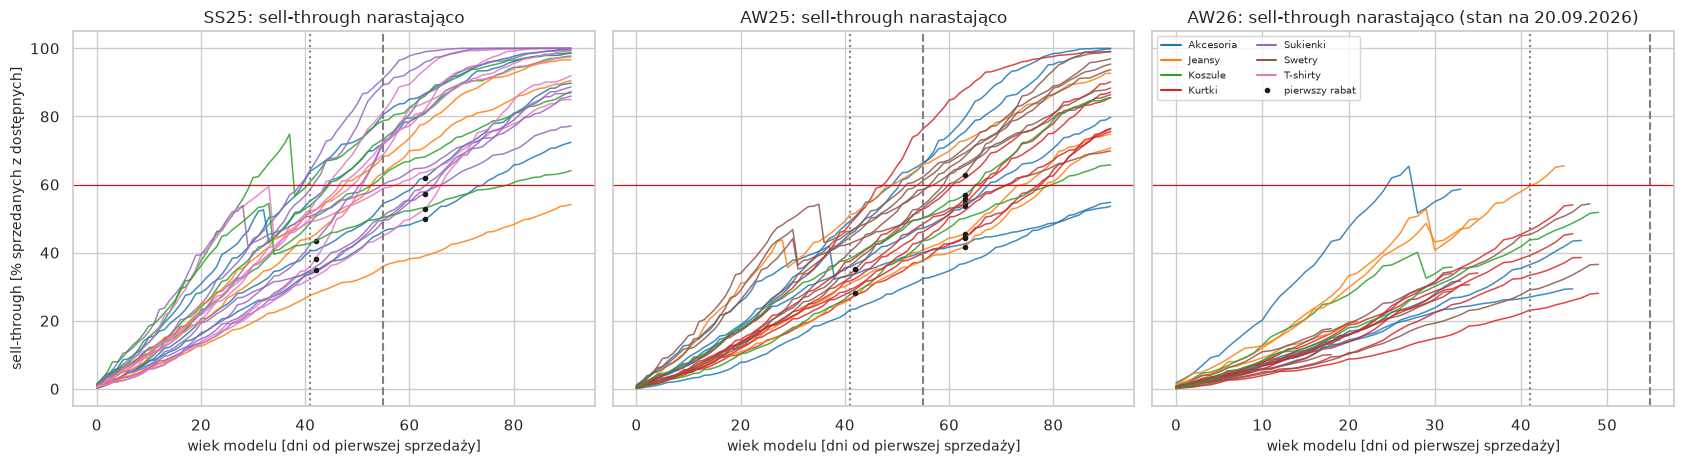

In [17]:
CAT = sku.drop_duplicates("StyleCode").set_index("StyleCode").Category
ms["Category"] = ms.StyleCode.map(CAT)
fd_map = mdl.set_index("StyleCode").first_disc_d
ms["first_disc_d"] = ms.StyleCode.map(fd_map)
EXPL = ["SS25", "AW25"]

piv = ms.pivot(index="StyleCode", columns="age_d", values="st")
sup = ms.pivot(index="StyleCode", columns="age_d", values="supply")
meta = ms.groupby("StyleCode").agg(Collection=("Collection", "first"), Category=("Category", "first"), first_disc_d=("first_disc_d", "first"))
meta["early_cut"] = meta.first_disc_d < 56                    # rabat przed końcem 8. tygodnia (dzień 55)
meta["restock"] = (sup[55].reindex(meta.index) / sup[0].reindex(meta.index) - 1).where(meta.Collection != "AW26")
meta["n0"] = sup[0].reindex(meta.index)

palette = dict(zip(sorted(CAT.unique()), sns.color_palette("tab10", 7)))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for ax, coll in zip(axes, ["SS25", "AW25", "AW26"]):
    for sc, g in ms[(ms.Collection == coll) & (ms.age_d <= 91)].groupby("StyleCode"):
        ax.plot(g.age_d, g.st * 100, color=palette[CAT[sc]], lw=1.1, alpha=0.85)
        f = meta.first_disc_d[sc]
        if f == f and f <= 91:
            ax.plot(f, g.set_index("age_d").st[f] * 100, "k.", ms=6)
    for x in (41, 55):
        ax.axvline(x, ls="--" if x == 55 else ":", color="gray")
    ax.axhline(60, color="red", lw=0.8)
    ax.set_title(f"{coll}: sell-through narastająco" + (" (stan na 20.09.2026)" if coll == "AW26" else ""))
    ax.set_xlabel("wiek modelu [dni od pierwszej sprzedaży]")
axes[0].set_ylabel("sell-through [% sprzedanych z dostępnych]")
from matplotlib.lines import Line2D
axes[2].legend([Line2D([0], [0], color=palette[c]) for c in palette] + [Line2D([0], [0], marker=".", color="k", ls="")],
               list(palette) + ["pierwszy rabat"], fontsize=7, loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

### 3.3 Rozkład etykiety: sell-through w dniu 55 (kolekcje eksploracyjne)

**Po co:** zobaczyć, jak często model nie osiąga 50/60/70% w 8. tygodniu i czy to zależy od kolekcji i kategorii. Etykieta ma sens tylko dla modeli bez rabatu do dnia 55, więc 5 modeli przecenionych w 7. tygodniu (w tych dwóch kolekcjach) liczę osobno. Zwracam też uwagę na to, ile modeli dostało uzupełnienie: ich sell-through jest liczony wobec większego mianownika.

Modele eksploracyjne: 48; czyste (bez rabatu do dnia 55): 43; przecenione wcześniej (cenzurowane): 5
Sell-through w dniu 55 wg kolekcji (modele czyste):


,modeli,mediana,min,max,<50%,<60%,<70%
Collection,,,,,,,
AW25,22.000,0.502,0.324,0.764,10.000,16.000,21.000
SS25,21.000,0.633,0.360,0.913,4.000,8.000,13.000


... wg kategorii (SS25 i AW25 razem; w AW25 tylko Kurtki, Swetry, Jeansy, Koszule, Akcesoria):


modeli  mediana   min   max  <50%  <60%  <70%
Collection Category                                                
AW25       Akcesoria   5.000    0.471 0.324 0.664 3.000 3.000 5.000
           Jeansy      3.000    0.409 0.378 0.660 2.000 2.000 3.000
           Koszule     1.000    0.503 0.503 0.503 0.000 1.000 1.000
           Kurtki      7.000    0.461 0.376 0.764 5.000 6.000 6.000
           Swetry      6.000    0.584 0.501 0.623 0.000 4.000 6.000
SS25       Akcesoria   4.000    0.633 0.463 0.806 1.000 2.000 2.000
           Jeansy      3.000    0.633 0.360 0.683 1.000 1.000 3.000
           Koszule     4.000    0.680 0.504 0.788 0.000 1.000 2.000
           Sukienki    5.000    0.601 0.496 0.913 1.000 2.000 3.000
           T-shirty    5.000    0.689 0.450 0.814 1.000 2.000 3.000

Modele przecenione od dnia 42 (cenzurowane): sell-through w dniach 41 i 55 (rabat od dnia 42 podbija wynik w dniu 55)


,Collection,Category,st41,st55,restock
StyleCode,,,,,
M-KNT-103,AW25,Swetry,0.337,0.539,0.000
M-SHI-104,AW25,Koszule,0.278,0.435,0.000
M-TSH-104,SS25,T-shirty,0.360,0.717,0.000
W-DRS-103,SS25,Sukienki,0.426,0.730,0.000
W-DRS-104,SS25,Sukienki,0.346,0.495,0.000


Dla porównania modele czyste: kwantyle sell-through w dniu 41: {0.1: 0.286, 0.25: 0.335, 0.5: 0.429, 0.75: 0.504, 0.9: 0.55}


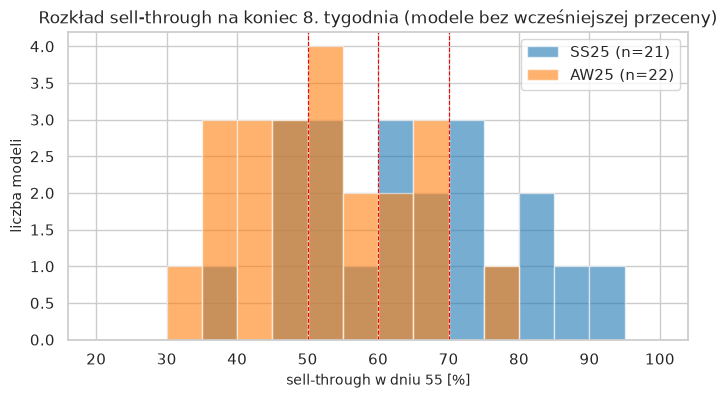

In [18]:
lab = meta.join(piv[[20, 41, 55]].rename(columns={20: "st20", 41: "st41", 55: "st55"}))
le = lab[lab.Collection.isin(EXPL)]
clean = le[~le.early_cut]
print(f"Modele eksploracyjne: {len(le)}; czyste (bez rabatu do dnia 55): {len(clean)}; przecenione wcześniej (cenzurowane): {int(le.early_cut.sum())}")

def summ(g):
    s = g.st55
    return pd.Series({"modeli": len(s), "mediana": s.median(), "min": s.min(), "max": s.max(),
                      "<50%": (s < .5).sum(), "<60%": (s < .6).sum(), "<70%": (s < .7).sum()})
print("Sell-through w dniu 55 wg kolekcji (modele czyste):")
display(clean.groupby("Collection").apply(summ, include_groups=False).round(3))
print("... wg kategorii (SS25 i AW25 razem; w AW25 tylko Kurtki, Swetry, Jeansy, Koszule, Akcesoria):")
display(clean.groupby(["Collection", "Category"]).apply(summ, include_groups=False).round(3))
print("Modele przecenione od dnia 42 (cenzurowane): sell-through w dniach 41 i 55 (rabat od dnia 42 podbija wynik w dniu 55)")
display(le[le.early_cut][["Collection", "Category", "st41", "st55", "restock"]].round(3))
print("Dla porównania modele czyste: kwantyle sell-through w dniu 41:", clean.st41.quantile([.1, .25, .5, .75, .9]).round(3).to_dict())

fig, ax = plt.subplots(figsize=(8, 4))
for coll, c in zip(EXPL, ["tab:blue", "tab:orange"]):
    ax.hist(clean[clean.Collection == coll].st55 * 100, bins=np.arange(20, 101, 5), alpha=0.6, label=f"{coll} (n={int((clean.Collection == coll).sum())})", color=c)
for t in (50, 60, 70):
    ax.axvline(t, color="red", lw=0.8, ls="--")
ax.set_xlabel("sell-through w dniu 55 [%]"); ax.set_ylabel("liczba modeli"); ax.set_title("Rozkład sell-through na koniec 8. tygodnia (modele bez wcześniejszej przeceny)"); ax.legend()
plt.show()

### 3.4 Wczesne tempo a sell-through na koniec 8. tygodnia (tylko eksploracja, bez progu decyzji)

**Po co:** sprawdzić, czy sell-through po 3, 4, 5, 6 tygodniach (to „tempo narastające") zapowiada wynik w dniu 55, i znaleźć modele, które łamią regułę (szybki start i wygasanie, wolny start i przyspieszenie). To jeszcze nie jest test H1 (formalne progi zapisuję w fazie 4), a przy 43 modelach to tylko opis kształtu zależności.

,moment,spearman_rho,pearson_r,n
0,dzień 13 (koniec tyg. 2),0.601,0.510,43
1,dzień 20 (koniec tyg. 3),0.632,0.502,43
2,dzień 27 (koniec tyg. 4),0.684,0.553,43
3,dzień 34 (koniec tyg. 5),0.826,0.787,43
4,dzień 41 (koniec tyg. 6),0.960,0.952,43


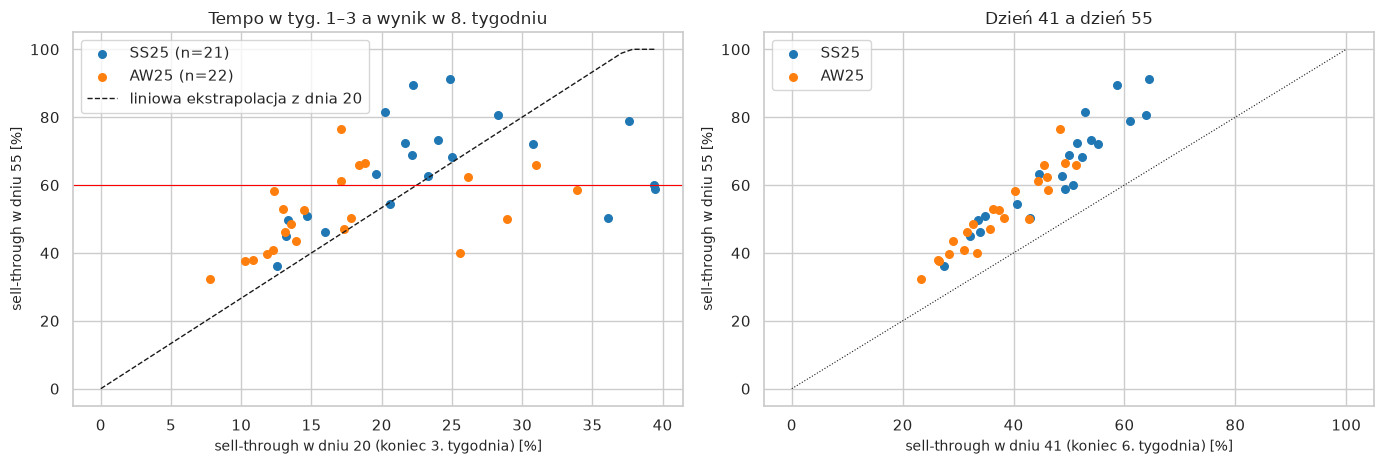

Modele odstające od liniowej ekstrapolacji z dnia 20 (największe |różnica|), 6 pozycji:


,Collection,Category,st20,lin_extr,st55,resid_lin,restock
StyleCode,,,,,,,
W-SHI-101,SS25,Koszule,0.361,0.964,0.504,-0.460,0.398
M-TSH-101,SS25,T-shirty,0.395,1.000,0.590,-0.410,0.375
W-DRS-102,SS25,Sukienki,0.394,1.000,0.601,-0.399,0.313
M-KNT-102,AW25,Swetry,0.339,0.904,0.585,-0.319,0.275
M-JKT-104,AW25,Kurtki,0.171,0.456,0.764,0.308,0.000
W-DRS-106,SS25,Sukienki,0.222,0.592,0.894,0.302,0.000


Średnia różnica (fakt − ekstrapolacja) wg kategorii (obciążenie ekstrapolacji), punkty procentowe:


count    mean    std
Collection Category                       
AW25       Akcesoria      5   3.500 18.900
           Jeansy         3   0.200 14.500
           Koszule        1   2.800    NaN
           Kurtki         7  13.300  8.100
           Swetry         6  -1.200 24.600
SS25       Akcesoria      4  -0.400  6.900
           Jeansy         3   5.100  5.300
           Koszule        4 -14.300 24.700
           Sukienki       5   8.200 28.000
           T-shirty       5   4.100 26.200

In [19]:
from scipy.stats import spearmanr
days = [13, 20, 27, 34, 41]
rows = []
for d in days:
    x = piv[d].reindex(clean.index)
    rho, p = spearmanr(x, clean.st55)
    rows.append(dict(moment=f"dzień {d} (koniec tyg. {(d + 1) // 7})", spearman_rho=rho, pearson_r=np.corrcoef(x, clean.st55)[0, 1], n=len(x)))
display(pd.DataFrame(rows).round(3))

# linia „liniowa ekstrapolacja z dnia 20": ST_55 ≈ ST_20 * 56/21 (stałe tempo, bez dostaw), do porównania z faktem
clean = clean.assign(lin_extr=lambda d: np.minimum(d.st20 * 56 / 21, 1.0))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for coll, c in zip(EXPL, ["tab:blue", "tab:orange"]):
    g = clean[clean.Collection == coll]
    axes[0].scatter(g.st20 * 100, g.st55 * 100, c=c, label=f"{coll} (n={len(g)})", s=30)
xs = np.linspace(0, clean.st20.max(), 50)
axes[0].plot(xs * 100, np.minimum(xs * 56 / 21, 1) * 100, "k--", lw=1, label="liniowa ekstrapolacja z dnia 20")
axes[0].axhline(60, color="red", lw=0.8)
axes[0].set_xlabel("sell-through w dniu 20 (koniec 3. tygodnia) [%]"); axes[0].set_ylabel("sell-through w dniu 55 [%]")
axes[0].set_title("Tempo w tyg. 1–3 a wynik w 8. tygodniu"); axes[0].legend()
for coll, c in zip(EXPL, ["tab:blue", "tab:orange"]):
    g = clean[clean.Collection == coll]
    axes[1].scatter(g.st41 * 100, g.st55 * 100, c=c, label=coll, s=30)
axes[1].plot([0, 100], [0, 100], "k:", lw=0.8)
axes[1].set_xlabel("sell-through w dniu 41 (koniec 6. tygodnia) [%]"); axes[1].set_ylabel("sell-through w dniu 55 [%]"); axes[1].set_title("Dzień 41 a dzień 55"); axes[1].legend()
plt.tight_layout(); plt.show()

clean["resid_lin"] = clean.st55 - clean.lin_extr
print("Modele odstające od liniowej ekstrapolacji z dnia 20 (największe |różnica|), 6 pozycji:")
display(clean.loc[clean.resid_lin.abs().sort_values(ascending=False).index[:6], ["Collection", "Category", "st20", "lin_extr", "st55", "resid_lin", "restock"]].round(3))
print("Średnia różnica (fakt − ekstrapolacja) wg kategorii (obciążenie ekstrapolacji), punkty procentowe:")
display((clean.groupby(["Collection", "Category"]).resid_lin.agg(["count", "mean", "std"]) * [1, 100, 100]).round(1))

**Co widzę (fakty) w fazie 3 (tylko SS25 i AW25, 43 modele bez wcześniejszej przeceny):**
- Sell-through w dniu 55: mediana AW25 ok. 50% (zakres 32–76%), SS25 ok. 63% (36–91%). Poniżej 60% jest 16 z 22 modeli AW25 i 8 z 21 modeli SS25; poniżej 50%: 10 i 4; poniżej 70%: 21 i 13.
- Pięć modeli przecenionych od dnia 42 ma w dniu 55 wynik wyższy niż w dniu 41 o 15–36 p.p. (np. 0,36 → 0,72); to potwierdza, że ich etykieta jest zmieszana z rabatem.
- Korelacja rang sell-through w dniu decyzji z wynikiem w dniu 55: 0,60 (dzień 13), 0,63 (20), 0,68 (27), 0,83 (34), 0,96 (41); n = 43.
- Błąd liniowej ekstrapolacji z dnia 20 (fakt − ekstrapolacja): kurtki średnio +13 p.p. (n = 7, sd 8), sukienki +8 p.p. (n = 5, sd 28), koszule SS25 −14 p.p. (n = 4, sd 25); rozrzut jest duży, a próby bardzo małe. Cztery z sześciu największych błędów (−46…−32 p.p.) to modele z uzupełnieniem dostaw 28–40% stanu początkowego.

**Wniosek / decyzja (interpretacja):** (1) wynik w dniu 55 jest w dużej mierze „zamknięty” już w dniu 41, a przed dniem 27 sell-through ma słabą moc predykcyjną, więc wartość metody leży w tygodniach 2–5; (2) uzupełnienia dostaw są największym źródłem „niespodzianek” etykiety i są nieznane w momencie decyzji; (3) próg 60% wypada w środku rozkładu obu kolekcji, więc wrażliwość na próg będzie duża.

### Dziennik pracy — Faza 3

- **Co zrobiłem:** pokazałem krzywe sell-through (SS25, AW25 i AW26 „do dziś"), rozkład etykiety w dniu 55 dla modeli bez wcześniejszej przeceny oraz zależność sell-through w dniach 13–41 od wyniku w dniu 55. Kolekcji SS26 w tej fazie celowo nie oglądałem pod kątem wyniku.
- **Co zobaczyłem:** kolekcje różnią się poziomem: AW25 ma medianę sell-through w dniu 55 ok. 50%, SS25 ok. 63%, więc próg 60% dzieli te zbiory zupełnie inaczej (AW25: 16 z 22 poniżej progu, SS25: 8 z 21). Korelacja rang wczesnego tempa z wynikiem rośnie z wiekiem: ρ ≈ 0,60 w dniu 13, 0,63 w dniu 20, 0,83 w dniu 34 i 0,96 w dniu 41. Odstające od liniowej ekstrapolacji to głównie modele z uzupełnieniem dostaw (mianownik rośnie) oraz kilka modeli z przyspieszeniem.
- **Co mnie zaskoczyło:** największe „pomyłki" ekstrapolacji (nawet −46 p.p.) nie wynikają z wygasania popytu, tylko z **uzupełnień dostaw w 5.–6. tygodniu**: model sprzedaje się dobrze, ktoś go uzupełnia, mianownik rośnie i sell-through w dniu 55 spada. To ważne dla interpretacji etykiety: „niski sell-through" może oznaczać zarówno wolną sprzedaż, jak i szybką sprzedaż z późniejszym uzupełnieniem.
- **Co zdecydowałem:** (1) nie zmieniam definicji etykiety (zgodna z definicją firmy), ale zapisuję w hipotezach i w wnioskach, że uzupełnienia są nieznane w momencie decyzji; (2) dodaję moment decyzji w 7. tygodniu (dzień 48), bo najstarsze modele AW26 mają dziś ok. 7 tygodni; (3) SS26 zostaje kolekcją testową.
- **Co odrzuciłem:** liniową ekstrapolację z dnia 20 jako samodzielną regułę (zawodzi dla modeli z uzupełnieniami).

## Faza 4 — Hipotezy i plan walidacji (zapisane PRZED budową modeli)

**Po co:** zapisuję hipotezy, miary i progi decyzji, zanim policzę jakikolwiek test lub model, żeby nie dopasowywać progów do wyniku. **Uczciwe zastrzeżenie:** w fazie 3 widziałem już opisowo wyniki SS25 i AW25 (rozrzut, korelacje rang, obciążenie ekstrapolacji z dnia 20 dla kurtek). Dlatego **testem potwierdzającym jest kolekcja SS26** (nie oglądałem jej wyniku), a wyniki z SS25 i AW25 traktuję jako eksploracyjne tam, gdzie je już widziałem. SS26 ma ok. 22 modele, więc przedziały będą szerokie: to jest ograniczenie, nie wada metody.

### 4.1 Etykieta, momenty decyzji, populacja

- **Etykieta:** `risk = 1`, gdy sell-through narastający w dniu 55 (koniec 8. tygodnia od pierwszej sprzedaży) jest niższy niż `τ = 60%` (wrażliwość: 50% i 70%). Definicja sell-through: słownik metryk Nordvik (sprzedane / (sprzedane + stan)), liczona narastająco, sumowana po SKU i lokalizacjach modelu, z uzupełnieniami dostaw w mianowniku.
- **Populacja:** modele z historii (SS25, AW25, SS26), które do dnia 55 nie miały rabatu (**66 z 72**). Sześć modeli z rabatem od dnia 42 jest cenzurowanych: ich etykieta jest zmieszana z efektem rabatu, więc nie wchodzą do treningu ani oceny (sprawdzę wrażliwość na ich włączenie).
- **Momenty decyzji:** końce tygodni 2–7 od pierwszej sprzedaży (dni 13, 20, 27, 34, 41, 48). Zlecenie wymienia tygodnie 2–6; tydzień 7 dodaję, bo dziś najstarsze modele AW26 (transza z 3 sierpnia) mają ok. 7 tygodni. Cechy tylko z danych do końca dnia decyzji. Wiersze z momentów, w których model miał już rabat, nie istnieją (rabat od dnia 42 dotyczy tylko modeli cenzurowanych).
- **Walidacja:** (a) leave-one-collection-out (LOCO): trening na dwóch kolekcjach, test na trzeciej; (b) „po czasie”: trening SS25 + AW25, test SS26 (potwierdzenie). Wszystkie wiersze jednego modelu (różne tygodnie) zawsze w jednym zbiorze. Przedziały: bootstrap po modelach (nie po wierszach), 90%, 1000 powtórzeń.
- **Metryki:** Brier score, log loss, AUC (uzupełniająco), wykres kalibracji, oczekiwany koszt decyzji. Źródło definicji sell-through: słownik metryk Nordvik; Brier, log loss i AUC to standardowe miary jakości prognoz prawdopodobieństw (nie mają odpowiednika w słowniku firmy).

### 4.2 Hipotezy i progi decyzji (poziom ufności 90%, dwustronnie; bootstrap po modelach)

| ID | Treść | Oczekiwany kierunek | Miara | Próg: potwierdzona / odrzucona |
|---|---|---|---|---|
| **H1a** | Wczesne tempo jest silnym predyktorem sell-through w dniu 55 | silna dodatnia zależność | korelacja rang Spearmana ρ(ST w dniu 20, ST w dniu 55), **SS26** | potwierdzona: ρ ≥ 0,60 **i** dolna granica przedziału > 0,40; odrzucona: ρ < 0,40; w pozostałych przypadkach niejednoznaczna |
| **H1b** | Zależność zawodzi dla modeli odstających (szybki start i wygasanie lub wolny start i przyspieszenie) | część modeli łamie regułę | udział modeli z \|ST55 − ekstrapolacja liniowa z dnia 20\| > 15 p.p. (wszystkie 66 modeli) | potwierdzona: udział ≥ 15% z dolną granicą przedziału > 5%; odrzucona: udział < 5% |
| **H2** | Liniowa ekstrapolacja tempa z ostatnich 2 tygodni jest obciążona w kategoriach sezonowych (zaniża, gdy sezon dopiero nabiera tempa) | residuum (fakt − ekstrapolacja, dzień 27) > 0 | średnie residuum per kategoria w p.p., przedział bootstrap | obciążona: \|średnia\| > 3 p.p. **i** przedział nie obejmuje 0; **kurtki i swetry opierają się na jednej kolekcji (AW25), więc wynik dla nich jest co najwyżej eksploracyjny, niepotwierdzalny** |
| **H3** | Model gradientowy (M2) nie pokona regresji logistycznej z kilkoma cechami (M1) | M2 nie lepszy | ΔBrier = Brier(M2) − Brier(M1), zbiorczo z LOCO, przedział bootstrap po modelach | H3 odrzucona (M2 lepszy) tylko jeśli **górna** granica przedziału ΔBrier < −0,01; w przeciwnym razie H3 potwierdzona (M2 nie jest wyraźnie lepszy) |
| **H4** | Cecha dostępności rozmiarów M i L poprawia predykcję | ΔBrier < 0 | ΔBrier = Brier(M1 z dostępnością) − Brier(M1 bez), LOCO, przedział bootstrap | potwierdzona: górna granica ΔBrier < −0,005; odrzucona: dolna granica ≥ 0 lub przedział obejmuje 0 z estymatą > −0,002; niejednoznaczna w pozostałych przypadkach |

**Pozostałe testy, które wykonam i pokażę (żeby nie ukryć wielokrotnych porównań):** ΔBrier B1 vs B0, B2 vs B1, M1 vs B2, M3 vs M1; porównania na poziomach τ = 50/70%; przegląd wyników osobno dla każdego momentu decyzji. Łącznie to ok. 15 porównań z jednego małego zbioru, więc przedziały traktuję jako informację, a nie jako formalne testy z kontrolą błędu I rodzaju (**brak korekty na wielokrotne porównania**).

### 4.3 Metryka decyzyjna zapisana z góry

Koszt decyzji liczę wg macierzy z 1.4 (δ = 20%, Δ = 25 p.p., h = 1,5%/mies., m = 2, ε = 50%, τ = 60%) na zaobserwowanych wolumenach historycznych. Polityki do porównania: (i) **nie flaguj nigdy** (przybliżenie braku wczesnego działania), (ii) **flaguj zawsze**, (iii) **„praktyka robocza” = flaguj, gdy sell-through jest poniżej prostej do celu** (`ST_d < τ · (d + 1) / 56`; to moje **ZAŁOŻENIE** o tym, jak wygląda dzisiejsze „na czuja”, a nie wiedza o procesie w firmie), (iv) reguły oparte na metodach z progiem. Próg decyzyjny wybieram **wyłącznie na zbiorach treningowych** danego foldu (nigdy na foldzie testowym).

**Kryterium użyteczności (zapisane z góry):** metoda jest warta wdrożenia, jeśli w LOCO jej koszt jest niższy niż koszt polityk (i)–(iii), a przedział bootstrap różnicy kosztu względem najlepszej z nich nie leży w całości po stronie gorszej. Jeśli żadna metoda tego nie osiągnie, rekomendacja brzmi: „reguła prosta i ostrożna”, z jawnym ostrzeżeniem.

## Transform — tabela modelowa (model × moment decyzji)

**Po co:** z dziennej serii modeli buduję tabelę, w której jeden wiersz to model w danym momencie decyzji, z cechami „as of” (tylko dane do końca dnia decyzji) oraz wynikiem w dniu 55 (do etykiety). Cechy:

- `st_d`: sell-through narastający w dniu decyzji (definicja ze słownika metryk);
- `rate14`: dzienne tempo sprzedaży z ostatnich 14 dni jako udział w dostępnych sztukach (`(Q_d − Q_{d−14}) / 14 / supply_d`);
- `pred55` (**B1**): ekstrapolacja liniowa `min(1, st_d_now + rate14 · (55 − d))`, liczona na dostępnych sztukach z dnia decyzji (zakłada brak uzupełnień);
- `trend`: logarytm stosunku sprzedaży z ostatnich 7 dni do sprzedaży z 7 dni wcześniej (`ln((u7_d + 1) / (u7_{d−7} + 1))`): czy tempo rośnie, czy maleje;
- `avail_core`: udział SKU (kolor × rozmiar) w rozmiarach M, L (i `ONE`) z dodatnim stanem w sieci;
- `restock`: `supply_d / supply_0 − 1` (uzupełnienia, które już wystąpiły do dnia decyzji, znane w momencie decyzji);
- `ln_price`: logarytm ceny netto modelu (znany przy premierze).

Wynik: `cum55`, `supply55`, `st55`, kwoty do kosztów (`Q_rest` = sztuki sprzedane po dniu decyzji do dnia 55).

In [20]:
DAYS = [13, 20, 27, 34, 41, 48]
TAU = COST["tau"]

P_ = {k: ms.pivot(index="StyleCode", columns="age_d", values=k) for k in ["cum", "supply", "stock", "st", "u7", "avail_core", "avail_all"]}
price = prod.groupby("StyleCode").agg(p=("net_price", "first"), c=("UnitCost", "first"))
mod = ms.groupby("StyleCode").agg(Collection=("Collection", "first"), Category=("Category", "first"), first_disc_d=("first_disc_d", "first"), age_max=("age_d", "max"))

def cum_at(day):
    """Sprzedaż narastająco w dniu `day` (0 przed pierwszą sprzedażą)."""
    return P_["cum"][day] if day >= 0 else pd.Series(0.0, index=P_["cum"].index)

def rows_at(d, models=None):
    ix = mod.index if models is None else models
    r = pd.DataFrame(index=ix)
    r["d"], r["k"] = d, (d + 1) // 7
    r["Collection"], r["Category"], r["first_disc_d"] = mod.Collection.reindex(ix), mod.Category.reindex(ix), mod.first_disc_d.reindex(ix)
    r["st_d"], r["cum_d"], r["supply_d"] = P_["st"][d].reindex(ix), P_["cum"][d].reindex(ix), P_["supply"][d].reindex(ix)
    r["rate14"] = ((cum_at(d) - cum_at(d - 14)) / 14 / P_["supply"][d]).reindex(ix)
    r["pred55"] = np.minimum(1.0, r.st_d + r.rate14 * (55 - d))
    r["trend"] = np.log((P_["u7"][d] + 1) / (P_["u7"][d - 7] + 1)).reindex(ix)
    r["avail_core"], r["avail_all"] = P_["avail_core"][d].reindex(ix), P_["avail_all"][d].reindex(ix)
    r["restock"] = (P_["supply"][d] / P_["supply"][0] - 1).reindex(ix)
    r["ln_price"] = np.log(price.p.reindex(ix))
    r["p"], r["c"] = price.p.reindex(ix), price.c.reindex(ix)
    r["cum55"], r["supply55"], r["st55"] = P_["cum"][55].reindex(ix), P_["supply"][55].reindex(ix), P_["st"][55].reindex(ix)
    r["q_rest"] = r.cum55 - r.cum_d
    return r.reset_index()

HIST = ["SS25", "AW25", "SS26"]
hist_models = mod.index[mod.Collection.isin(HIST)]
D_all = pd.concat([rows_at(d, hist_models) for d in DAYS], ignore_index=True)
D_all["censored"] = D_all.first_disc_d < 56                       # rabat przed końcem 8. tyg.: etykieta zmieszana z przeceną
D_all["disc_in_features"] = D_all.first_disc_d <= D_all.d          # rabat już w oknie cech
D = D_all[~D_all.censored].reset_index(drop=True)
print("Wiersze (model x moment): wszystkie", len(D_all), "| po wykluczeniu cenzurowanych", len(D), "| w cechach rabat:", int(D.disc_in_features.sum()))
print("Modele czyste wg kolekcji:", D.groupby("Collection").StyleCode.nunique().to_dict(), "| cenzurowane:", D_all[D_all.censored].groupby("Collection").StyleCode.nunique().to_dict())
print("Braki w cechach:", int(D[["st_d", "rate14", "pred55", "trend", "avail_core", "restock", "ln_price", "st55"]].isna().any(axis=1).sum()))
display(D[D.Collection.isin(["SS25", "AW25"])].groupby("k").agg(modeli=("StyleCode", "nunique"), baza_ryzyka_tau60=("st55", lambda s: (s < TAU).mean())).round(3).T)
display(D[D.k == 3].head(4)[["StyleCode", "Collection", "Category", "st_d", "rate14", "pred55", "trend", "avail_core", "restock", "ln_price"]].round(3))

Wiersze (model x moment): wszystkie 432 | po wykluczeniu cenzurowanych 396 | w cechach rabat: 0
Modele czyste wg kolekcji: {'AW25': 22, 'SS25': 21, 'SS26': 23} | cenzurowane: {'AW25': 2, 'SS25': 3, 'SS26': 1}
Braki w cechach: 0


k,2,3,4,5,6,7
modeli,43.000,43.000,43.000,43.000,43.000,43.000
baza_ryzyka_tau60,0.558,0.558,0.558,0.558,0.558,0.558


,StyleCode,Collection,Category,st_d,rate14,pred55,trend,avail_core,restock,ln_price
66,A-BAG-101,SS25,Akcesoria,0.206,0.011,0.599,0.199,1.000,0.000,5.086
67,A-BAG-102,SS25,Akcesoria,0.308,0.017,0.889,-0.052,1.000,0.000,5.086
68,A-BAG-103,SS25,Akcesoria,0.159,0.008,0.441,0.063,1.000,0.000,5.269
69,A-BAG-104,SS25,Akcesoria,0.283,0.014,0.769,0.231,1.000,0.000,5.526


## Faza 5 — Baseline'y i ramy oceny

**Po co:** zanim zbuduję jakikolwiek model, potrzebuję (1) jednej, wspólnej procedury oceny dla wszystkich metod i (2) prostych punktów odniesienia. Jeśli złożona metoda nie pobije punktu odniesienia, nie ma po co jej używać.

**Procedura oceny (zapisana w 4.1):** podział po kolekcjach (leave-one-collection-out, LOCO): metoda jest uczona na dwóch kolekcjach i oceniana na trzeciej, a wszystkie wiersze jednego modelu zawsze trafiają do jednego zbioru. Fold „test = SS26” jest zarazem testem „po czasie” (trening na SS25 i AW25). Z predykcji ze wszystkich trzech foldów składam jedną tabelę „out-of-fold”, a niepewność liczę **bootstrapem po modelach** (losuję całe modele, nie wiersze). Próg decyzyjny wybieram na predykcjach z **wewnętrznego LOCO na kolekcjach treningowych** danego foldu (trening na jednej kolekcji, predykcja drugiej), nigdy na foldzie testowym.

**Punkty odniesienia:**
- **B0**: częstość bazowa ryzyka w treningu, w wersji globalnej (B0g) i wg kategorii skurczonej do globalnej (B0; jeśli kategorii nie ma w treningu, wartość globalna).
- **B1**: ekstrapolacja liniowa tempa z ostatnich 14 dni na dzień 55 (`pred55`); prawdopodobieństwo ryzyka wynika z założenia, że błąd ekstrapolacji ma rozkład normalny z odchyleniem policzonym na treningu osobno dla każdego momentu decyzji: `P = Φ((τ − pred55) / σ_k)`.
- **B2**: jak B1, ale z korektą średniego błędu per kategoria (skurczoną o wagę `n/(n+30)`, czyli ok. 5 modeli), policzoną na treningu.

**Polityki bez modelu** (do porównania kosztów): „nie flaguj nigdy”, „flaguj zawsze” i „praktyka robocza” (flaguj, gdy `ST_d < τ·(d+1)/56`, **ZAŁOŻENIE** o tym, jak mniej więcej wygląda dzisiejsze „na czuja”).

**Koszt decyzji** (macierz z 1.4): `K_flag = δ·p·Q_rest`, `K_miss = S·(Δ·p + h·m·c)` z `S = max(0, τ·dostępne_55 − sprzedane_55)`; bez flagi płacimy `K_miss`, z flagą `K_flag + (1 − ε)·K_miss`. Każdy moment decyzji oceniam niezależnie (jakby decyzja zapadała tylko wtedy).

In [21]:
from scipy.stats import norm, spearmanr
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

COLLS = ["SS25", "AW25", "SS26"]
EPS = COST["eps"]
GRID = np.round(np.arange(0.05, 0.96, 0.05), 2)

def label(df, tau):
    return (df.st55 < tau).astype(int).to_numpy()

def cost_table(df, tau, delta=None, d_clear=None, eps=None, hold=None):
    """Koszt per wiersz: bez flagi (c_no) i z flagą (c_flag), PLN netto. Parametry nadpisywalne do analizy wrażliwości."""
    delta = COST["delta"] if delta is None else delta
    d_clear = COST["delta_clear"] if d_clear is None else d_clear
    eps = EPS if eps is None else eps
    hold = COST["hold_m"] if hold is None else hold
    S = np.maximum(0.0, tau * df.supply55 - df.cum55)
    k_miss = (S * (d_clear * df.p + hold * COST["hold_months"] * df.c)).to_numpy()
    k_flag = (delta * df.p * df.q_rest).to_numpy()
    return pd.DataFrame({"c_no": k_miss, "c_flag": k_flag + (1 - eps) * k_miss, "k_flag": k_flag, "k_miss": k_miss}, index=df.index)

def theory_threshold(df, tau, **kw):
    """P* = K_flag_sr / (eps * K_miss_sr_wsrod_ryzykownych), osobno dla tygodnia decyzji k; z wierszy treningowych (nie z foldu testowego)."""
    ct, y = cost_table(df, tau, **kw), pd.Series(label(df, tau), index=df.index)
    eps = EPS if kw.get("eps") is None else kw["eps"]
    out = {}
    for k_, ix in df.groupby("k").groups.items():
        out[k_] = float(np.clip(ct.loc[ix, "k_flag"].mean() / (eps * ct.loc[ix, "k_miss"].sum() / max(y.loc[ix].sum(), 1)), 0.02, 0.98))
    return out

def pick_threshold(df, p, tau, **kw):
    """Próg osobno dla każdego tygodnia decyzji k (koszt flagi zależy od tego, ile sprzedaży zostało do dnia 55). Przy remisie wybieram wyższy próg (nie flaguję bez korzyści)."""
    ct, out = cost_table(df, tau, **kw), {}
    c_flag, c_no = ct.c_flag.to_numpy(), ct.c_no.to_numpy()
    for k_, ix in df.reset_index(drop=True).groupby("k").indices.items():
        tot = [np.where(p[ix] > t, c_flag[ix], c_no[ix]).sum() for t in GRID]
        out[k_] = float(GRID[np.isclose(tot, np.min(tot))].max())
    return out

def _sigma(resid, k_tr, k_te):
    s = pd.Series(resid).groupby(k_tr).std(ddof=1)
    return np.maximum(pd.Series(k_te).map(s).fillna(s.mean()).to_numpy(), 0.03)

def m_B0g(tr, te, tau):
    return np.full(len(te), label(tr, tau).mean())

def m_B0(tr, te, tau):
    y = pd.Series(label(tr, tau), index=tr.index)
    n, g = tr.groupby("Category").size(), y.mean()
    w = n / (n + 30)
    est = w * y.groupby(tr.Category).mean() + (1 - w) * g
    return te.Category.map(est).fillna(g).to_numpy()

def m_B1(tr, te, tau):
    s = _sigma((tr.st55 - tr.pred55).to_numpy(), tr.k.to_numpy(), te.k.to_numpy())
    return norm.cdf((tau - te.pred55.to_numpy()) / s)

def m_B2(tr, te, tau):
    res = tr.st55 - tr.pred55
    n = tr.groupby("Category").size()
    bias = res.groupby(tr.Category).mean() * (n / (n + 30))
    s = _sigma((res - tr.Category.map(bias)).to_numpy(), tr.k.to_numpy(), te.k.to_numpy())
    mu = te.pred55 + te.Category.map(bias).fillna(0.0)
    return norm.cdf((tau - mu.to_numpy()) / s)

def run_cv(methods, tau, data=None):
    """LOCO: predykcje out-of-fold + progi (wybrany na wewnętrznym LOCO oraz teoretyczny) liczone tylko z danych treningowych."""
    data = D if data is None else data
    outs = []
    for test_c in COLLS:
        tr, te = data[data.Collection != test_c], data[data.Collection == test_c]
        o = te.copy()
        o["y"] = label(te, tau)
        for name, f in methods.items():
            inner = pd.concat([pd.Series(f(tr[tr.Collection != c], tr[tr.Collection == c], tau), index=tr[tr.Collection == c].index)
                               for c in tr.Collection.unique()])
            o["p__" + name] = f(tr, te, tau)
            o["thr__" + name] = te.k.map(pick_threshold(tr.loc[inner.index], inner.to_numpy(), tau)).to_numpy()
        o["thr_theory"] = te.k.map(theory_threshold(tr, tau)).to_numpy()
        outs.append(o)
    return pd.concat(outs, ignore_index=True)

def boot_setup(O, B=1000, seed=SEED):
    ids = O.StyleCode.unique()
    return ids, np.random.default_rng(seed).multinomial(len(ids), np.ones(len(ids)) / len(ids), size=B)

def _by_model(O, vals, ids):
    t = pd.DataFrame({"v": np.asarray(vals, float), "n": 1.0, "id": O.StyleCode.to_numpy()}).groupby("id").sum().reindex(ids)
    return t.v.to_numpy(), t.n.to_numpy()

def boot_mean(O, vals, bs):
    """Średnia po wierszach z przedziałem 90% z bootstrapu po modelach."""
    ids, W = bs
    v, n = _by_model(O, vals, ids)
    return v.sum() / n.sum(), np.quantile((W @ v) / (W @ n), [0.05, 0.95])

def boot_diff(O, va, vb, bs):
    ids, W = bs
    a, n = _by_model(O, va, ids)
    b, _ = _by_model(O, vb, ids)
    return (a.sum() - b.sum()) / n.sum(), np.quantile((W @ (a - b)) / (W @ n), [0.05, 0.95])

def sq_err(O, m):
    return (O["p__" + m] - O.y) ** 2

def log_loss_rows(O, m):
    p = O["p__" + m].clip(1e-3, 1 - 1e-3)
    return -(O.y * np.log(p) + (1 - O.y) * np.log(1 - p))

def policy_cost(O, tau, flag, **kw):
    ct = cost_table(O, tau, **kw)
    return np.where(flag, ct.c_flag, ct.c_no)

def rule_cost(O, m, tau, which="tuned", **kw):
    thr = O["thr__" + m] if which == "tuned" else O["thr_theory"]
    return policy_cost(O, tau, O["p__" + m] > thr, **kw)

def basic_policies(O, tau):
    return {"nie flaguj nigdy": np.zeros(len(O), bool), "flaguj zawsze": np.ones(len(O), bool),
            "praktyka robocza (ST < prosta do celu)": (O.st_d < tau * (O.d + 1) / 56).to_numpy()}

def eval_table(O, methods, tau, bs):
    rows = []
    for m in methods:
        br, brci = boot_mean(O, sq_err(O, m), bs)
        ll, llci = boot_mean(O, log_loss_rows(O, m), bs)
        co, coci = boot_mean(O, rule_cost(O, m, tau), bs)
        cth, _ = boot_mean(O, rule_cost(O, m, tau, "theory"), bs)
        rows.append({"metoda": m, "Brier": br, "Brier 90% od": brci[0], "Brier 90% do": brci[1], "log loss": ll,
                     "AUC": roc_auc_score(O.y, O["p__" + m]) if O["p__" + m].nunique() > 1 else 0.5,
                     "koszt/wiersz (próg z walidacji)": co, "koszt od": coci[0], "koszt do": coci[1], "koszt (próg teoretyczny)": cth})
    for name, fl in basic_policies(O, tau).items():
        c_, cci = boot_mean(O, policy_cost(O, tau, fl), bs)
        rows.append({"metoda": "[polityka] " + name, "koszt/wiersz (próg z walidacji)": c_, "koszt od": cci[0], "koszt do": cci[1]})
    return pd.DataFrame(rows).set_index("metoda")

**Po co kolejna komórka:** uruchamiam B0–B2 w procedurze LOCO przy τ = 60% i pokazuję jakość prognoz prawdopodobieństwa (Brier, log loss, AUC) oraz koszt decyzji. Wszystkie liczby dotyczą 66 modeli (396 wierszy model × moment); przedziały to 90% bootstrapu po modelach. Koszt jest średnią na wiersz (jeden model w jednym momencie decyzji), w PLN netto.

In [22]:
BASE = {"B0g": m_B0g, "B0": m_B0, "B1": m_B1, "B2": m_B2}
O_base = run_cv(BASE, TAU)
BS = boot_setup(O_base)
print("Wiersze out-of-fold:", len(O_base), "| modele:", O_base.StyleCode.nunique(), "| udział ryzykownych (tau=60%):", round(O_base.y.mean(), 3))
tab5 = eval_table(O_base, BASE, TAU, BS)
display(tab5.round(4))
print("Brier osobno dla foldów (kolekcja testowa) i dla momentów decyzji (tydzień k):")
display(pd.DataFrame({m: (O_base.assign(se=sq_err(O_base, m)).groupby("Collection").se.mean()) for m in BASE}).round(3))
display(pd.DataFrame({m: (O_base.assign(se=sq_err(O_base, m)).groupby("k").se.mean()) for m in BASE}).T.round(3))
print("Progi decyzyjne dla B1: wybrany na walidacji wewnętrznej (wiersze: kolekcja testowa, kolumny: tydzień k) oraz teoretyczny P* = K_flag/(ε·K_miss):")
display(O_base.groupby(["Collection", "k"]).thr__B1.first().unstack().round(2))
display(O_base.groupby(["Collection", "k"]).thr_theory.first().unstack().round(2))

Wiersze out-of-fold: 396 | modele: 66 | udział ryzykownych (tau=60%): 0.47


,Brier,Brier 90% od,Brier 90% do,log loss,AUC,koszt/wiersz (próg z walidacji),koszt od,koszt do,koszt (próg teoretyczny)
metoda,,,,,,,,,
B0g,0.292,0.272,0.311,0.781,0.311,"21,691.706","14,004.613","30,895.938","21,691.706"
B0,0.276,0.252,0.297,0.749,0.357,"21,691.706","14,004.613","30,895.938","21,691.706"
B1,0.118,0.087,0.150,0.402,0.918,"22,576.630","14,887.036","31,750.108","21,486.960"
B2,0.122,0.088,0.159,0.429,0.912,"22,887.584","15,243.258","32,027.600","21,619.515"
[polityka] nie flaguj nigdy,NaN,NaN,NaN,NaN,NaN,"21,691.706","14,004.613","30,895.938",NaN
[polityka] flaguj zawsze,NaN,NaN,NaN,NaN,NaN,"58,142.823","50,068.399","68,380.320",NaN
[polityka] praktyka robocza (ST < prosta do celu),NaN,NaN,NaN,NaN,NaN,"39,937.671","30,485.800","50,828.209",NaN


Brier osobno dla foldów (kolekcja testowa) i dla momentów decyzji (tydzień k):


,B0g,B0,B1,B2
Collection,,,,
AW25,0.348,0.347,0.124,0.128
SS25,0.253,0.236,0.117,0.119
SS26,0.276,0.245,0.113,0.119


k,2,3,4,5,6,7
B0g,0.293,0.293,0.293,0.293,0.293,0.293
B0,0.276,0.276,0.276,0.276,0.276,0.276
B1,0.248,0.182,0.148,0.089,0.025,0.015
B2,0.249,0.179,0.144,0.093,0.042,0.024


Progi decyzyjne dla B1: wybrany na walidacji wewnętrznej (wiersze: kolekcja testowa, kolumny: tydzień k) oraz teoretyczny P* = K_flag/(ε·K_miss):


k,2,3,4,5,6,7
Collection,,,,,,
AW25,0.950,0.950,0.950,0.950,0.950,0.950
SS25,0.950,0.950,0.950,0.950,0.950,0.950
SS26,0.950,0.950,0.950,0.950,0.950,0.950


k,2,3,4,5,6,7
Collection,,,,,,
AW25,0.980,0.980,0.980,0.980,0.890,0.460
SS25,0.980,0.980,0.980,0.980,0.980,0.570
SS26,0.980,0.980,0.980,0.980,0.980,0.770


### Testy hipotez H1 i H2 (progi zapisane w 4.2)

**Po co:** H1 i H2 dotyczą samej zależności tempa od wyniku i obciążenia ekstrapolacji, więc mogę je sprawdzić już na B1. Każdy test: korelacja rang Spearmana (bez założeń o rozkładzie) lub średnia z bootstrapu po modelach, poziom ufności 90% dwustronnie (alfa = 0,10). Wszystkie wykonane testy pokazuję w jednej tabeli.

,hipoteza,zbiór,n modeli,estymata,90% od,90% do,werdykt wg progu
0,"H1a: rho(ST_20, ST_55)",SS26 (potwierdzenie),23,0.522,0.156,0.802,niejednoznaczna
1,"H1a: rho(ST_20, ST_55)",SS25+AW25 (eksploracja),43,0.632,0.420,0.786,(informacyjnie)
2,"H1a: rho(ST_20, ST_55)",wszystkie 66 modeli,66,0.632,0.457,0.757,(informacyjnie)
3,"(kontekst) rho(ST_13, ST_55)",wszystkie 66 modeli,66,0.612,0.431,0.747,(informacyjnie)
4,"(kontekst) rho(ST_27, ST_55)",wszystkie 66 modeli,66,0.671,0.496,0.805,(informacyjnie)
5,"(kontekst) rho(ST_34, ST_55)",wszystkie 66 modeli,66,0.818,0.709,0.894,(informacyjnie)
6,"(kontekst) rho(ST_41, ST_55)",wszystkie 66 modeli,66,0.944,0.894,0.968,(informacyjnie)
7,"(kontekst) rho(ST_48, ST_55)",wszystkie 66 modeli,66,0.987,0.971,0.991,(informacyjnie)
8,H1b: udział |ST55 - B1| > 15 p.p. (dzień 20),wszystkie 66 modeli,66,0.348,0.258,0.439,potwierdzona


,kategoria,n modeli,kolekcje,średnie residuum [p.p.],90% od,90% do,obciążona wg progu (|śr.|>3 p.p. i przedział bez 0),pewność
0,Akcesoria,13,"AW25, SS25, SS26",-9.690,-17.430,-2.450,tak,dwie lub trzy kolekcje
1,Jeansy,9,"AW25, SS25, SS26",-3.800,-9.450,0.790,nie,dwie lub trzy kolekcje
2,Koszule,9,"AW25, SS25, SS26",-13.550,-23.250,-4.680,tak,dwie lub trzy kolekcje
3,Kurtki,7,AW25,5.440,2.610,9.510,tak,jedna kolekcja: tylko eksploracja
4,Sukienki,11,"SS25, SS26",-1.030,-9.880,6.430,nie,dwie lub trzy kolekcje
5,Swetry,6,AW25,-17.210,-32.050,-3.380,tak,jedna kolekcja: tylko eksploracja
6,T-shirty,11,"SS25, SS26",0.790,-7.400,7.240,nie,dwie lub trzy kolekcje


Residuum = ST w dniu 55 minus B1 (ekstrapolacja liniowa z 14 dni, dzień 27); dodatnie = ekstrapolacja zaniża wynik.


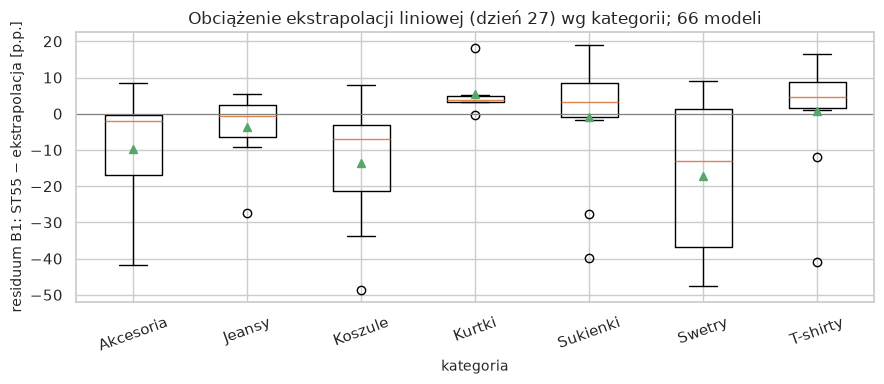

In [23]:
rng_t = np.random.default_rng(SEED + 1)

def boot_spearman(x, y, B=2000):
    n = len(x)
    ix = rng_t.integers(0, n, size=(B, n))
    r = np.array([spearmanr(x[i], y[i])[0] for i in ix])
    return np.nanquantile(r, [0.05, 0.95])

tests = []
# H1a: SS26 (potwierdzenie) oraz, informacyjnie, kolekcje SS25/AW25 i wszystkie modele; moment: dzień 20 (tydzień 3)
for lbl, sub in [("SS26 (potwierdzenie)", D[(D.k == 3) & (D.Collection == "SS26")]),
                 ("SS25+AW25 (eksploracja)", D[(D.k == 3) & D.Collection.isin(["SS25", "AW25"])]),
                 ("wszystkie 66 modeli", D[D.k == 3])]:
    rho = spearmanr(sub.st_d, sub.st55)[0]
    lo, hi = boot_spearman(sub.st_d.to_numpy(), sub.st55.to_numpy())
    verdict = "potwierdzona" if (rho >= 0.60 and lo > 0.40) else ("odrzucona" if rho < 0.40 else "niejednoznaczna")
    tests.append({"hipoteza": "H1a: rho(ST_20, ST_55)", "zbiór": lbl, "n modeli": len(sub), "estymata": rho, "90% od": lo, "90% do": hi,
                  "werdykt wg progu": verdict if lbl.startswith("SS26") else "(informacyjnie)"})
# kontekst: ta sama korelacja w innych momentach decyzji, wszystkie modele
for k_ in [2, 4, 5, 6, 7]:
    sub = D[D.k == k_]
    rho = spearmanr(sub.st_d, sub.st55)[0]
    lo, hi = boot_spearman(sub.st_d.to_numpy(), sub.st55.to_numpy(), 1000)
    tests.append({"hipoteza": f"(kontekst) rho(ST_{7 * k_ - 1}, ST_55)", "zbiór": "wszystkie 66 modeli", "n modeli": len(sub), "estymata": rho, "90% od": lo, "90% do": hi, "werdykt wg progu": "(informacyjnie)"})
# H1b: udział modeli odstających od B1 (|ST55 - pred55| > 15 p.p.) w dniu 20
d3 = D[D.k == 3]
out_ = ((d3.st55 - d3.pred55).abs() > 0.15).to_numpy()
bsh = [rng_t.choice(out_, len(out_)).mean() for _ in range(2000)]
lo, hi = np.quantile(bsh, [0.05, 0.95])
tests.append({"hipoteza": "H1b: udział |ST55 - B1| > 15 p.p. (dzień 20)", "zbiór": "wszystkie 66 modeli", "n modeli": len(d3), "estymata": out_.mean(), "90% od": lo, "90% do": hi,
              "werdykt wg progu": "potwierdzona" if (out_.mean() >= 0.15 and lo > 0.05) else ("odrzucona" if out_.mean() < 0.05 else "niejednoznaczna")})
display(pd.DataFrame(tests).round(3))

# H2: obciążenie B1 per kategoria w dniu 27 (tydzień 4)
d4 = D[D.k == 4].assign(res=lambda d: (d.st55 - d.pred55) * 100)
rows = []
for cat, g in d4.groupby("Category"):
    v = g.res.to_numpy()
    b = [rng_t.choice(v, len(v)).mean() for _ in range(2000)]
    lo, hi = np.quantile(b, [0.05, 0.95])
    sig = abs(v.mean()) > 3 and not (lo <= 0 <= hi)
    rows.append({"kategoria": cat, "n modeli": len(v), "kolekcje": ", ".join(sorted(g.Collection.unique())), "średnie residuum [p.p.]": v.mean(), "90% od": lo, "90% do": hi,
                 "obciążona wg progu (|śr.|>3 p.p. i przedział bez 0)": "tak" if sig else "nie",
                 "pewność": "jedna kolekcja: tylko eksploracja" if g.Collection.nunique() == 1 else "dwie lub trzy kolekcje"})
display(pd.DataFrame(rows).round(2))
print("Residuum = ST w dniu 55 minus B1 (ekstrapolacja liniowa z 14 dni, dzień 27); dodatnie = ekstrapolacja zaniża wynik.")
fig, ax = plt.subplots(figsize=(9, 4))
order = sorted(d4.Category.unique())
ax.boxplot([d4[d4.Category == c].res for c in order], tick_labels=order, showmeans=True)
ax.axhline(0, color="gray", lw=0.8)
ax.set_ylabel("residuum B1: ST55 − ekstrapolacja [p.p.]"); ax.set_xlabel("kategoria"); ax.set_title("Obciążenie ekstrapolacji liniowej (dzień 27) wg kategorii; 66 modeli")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

## Faza 6 — Metody

**Po co:** sprawdzam, czy cokolwiek poza ekstrapolacją liniową poprawia prognozę ryzyka, i jaką cenę (złożoność, niestabilność) za to płacę. Wszystko w tej samej procedurze LOCO i na tych samych 66 modelach. Metody, od prostych:

- **M1a** — regresja logistyczna (standaryzowane cechy, kara L2 `C = 1`) na 7 cechach z sekcji Transform: `pred55`, `st_d`, `trend`, `avail_core`, `restock`, `ln_price`, `k` (numer tygodnia). To metoda główna (H3 i H4 odnoszą się do niej).
- **Ablacje M1a** (po jednej cesze mniej): bez `avail_core` (test H4), bez `ln_price` (podejrzewam, że cena „wyciąga" model poza zakres treningu, bo kurtki są kilka razy droższe niż cokolwiek w SS), bez `restock`.
- **M1r** — regresja liniowa (ridge) na ciągły sell-through w dniu 55, z normalnym przedziałem predykcji; prawdopodobieństwo ryzyka to `Φ((τ − μ)/σ_k)`. Alternatywa dla M1a, którą dopuszcza zlecenie.
- **M2** — model gradientowy (LightGBM): głębokość 2, 4 liście, 150 drzew, krok 0,03, silna regularyzacja (`reg_lambda = 5`, `min_child_samples = 20`, próbkowanie 80%); cechy jak M1a plus `rate14`, `avail_all`, kod kategorii. Kalibracja: brak / Platt / izotoniczna, oparte na predykcjach out-of-fold z wewnętrznej walidacji grupowanej po modelach.
- **M3** — parametryczna krzywa sprzedaży per model: sprzedaż narastająca `C(t) = A·(1 − exp(−(t + 1)/θ))` dopasowana do dziennych danych do dnia decyzji (nieliniowe najmniejsze kwadraty, `A ≥ C_d`, `θ ∈ [2, 400]`), ekstrapolacja do dnia 55 na dostępnych sztukach z dnia decyzji (bez uzupełnień). Niepewność dopasowania z bootstrapu reszt (40 powtórzeń) sumuję z odchyleniem błędu z treningu: `P = Φ((τ − μ₃ − b_k)/√(s_fit² + σ_k²))`. To metoda strukturalna, która ma odpowiedzieć na pytanie, czy kształt krzywej pomaga ponad zwykłe tempo.

**Higiena:** wybór wariantu metody na podstawie zbiorczych wyników LOCO to też forma dopasowania do danych. Dlatego M1a jest wskazana z góry jako metoda główna, a warianty traktuję jako ablacje, nie jako konkurencję do wyboru najlepszego.

In [24]:
import lightgbm as lgb
from scipy.optimize import curve_fit
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import GroupKFold

CATS = sorted(D_all.Category.unique())
for _df in (D, D_all):
    _df["cat"] = _df.Category.map({c: i for i, c in enumerate(CATS)})

FE_M1 = ["pred55", "st_d", "trend", "avail_core", "restock", "ln_price", "k"]

def make_logit(feats, C=1.0):
    def f(tr, te, tau):
        m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000)).fit(tr[feats], label(tr, tau))
        return m.predict_proba(te[feats])[:, 1]
    return f

def make_ridge(feats, alpha=3.0):
    def f(tr, te, tau):
        m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(tr[feats], tr.st55)
        res = (tr.st55 - m.predict(tr[feats])).to_numpy() * np.sqrt(len(tr) / (len(tr) - len(feats) - 1))  # poprawka na liczbę parametrów
        return norm.cdf((tau - m.predict(te[feats])) / _sigma(res, tr.k.to_numpy(), te.k.to_numpy()))
    return f

FE_M2 = FE_M1 + ["rate14", "avail_all", "cat"]

def _gbm():
    return lgb.LGBMClassifier(n_estimators=150, learning_rate=0.03, max_depth=2, num_leaves=4, min_child_samples=20, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, reg_lambda=5.0, random_state=SEED, verbose=-1, n_jobs=1)

def _logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))

def make_gbm(feats, cal=None):
    def f(tr, te, tau):
        X, y = tr[feats], label(tr, tau)
        p_te = _gbm().fit(X, y).predict_proba(te[feats])[:, 1]
        if cal is None:
            return p_te
        oof = np.zeros(len(tr))
        for a, b in GroupKFold(5).split(X, y, tr.StyleCode):
            oof[b] = _gbm().fit(X.iloc[a], y[a]).predict_proba(X.iloc[b])[:, 1]
        if cal == "platt":
            return LogisticRegression(C=1e6).fit(_logit(oof).reshape(-1, 1), y).predict_proba(_logit(p_te).reshape(-1, 1))[:, 1]
        return IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(oof, y).predict(p_te)
    return f

# M3: dopasowanie krzywej nasycenia do sprzedaży narastającej danego modelu do dnia decyzji (tylko jego własne dane do tego dnia)
def _curve(t, A, th):
    return A * (1 - np.exp(-(t + 1) / th))

def fit_curve(cum_series, d, n_boot=40, seed=0):
    t = np.arange(d + 1, dtype=float)
    y = cum_series[: d + 1].astype(float)
    cd = y[-1]
    def one(yy):
        try:
            p, _ = curve_fit(_curve, t, yy, p0=[cd * 1.5, 40.0], bounds=([max(cd, 1.0), 2.0], [cd * 8 + 10, 400.0]), maxfev=4000)
            return p
        except Exception:
            return np.array([np.nan, np.nan])
    p0 = one(y)
    if np.isnan(p0[0]):
        return np.nan, np.nan
    res = y - _curve(t, *p0)
    rg = np.random.default_rng(seed)
    c55 = [_curve(55.0, *one(np.maximum.accumulate(_curve(t, *p0) + rg.choice(res, len(res))))) for _ in range(n_boot)]
    return _curve(55.0, *p0), float(np.nanstd(c55))

M3_FILE = CACHE / "m3_curve_fits.parquet"

def m3_columns(rows):
    """Dla każdego wiersza (model, dzień): ekstrapolowana sprzedaż w dniu 55 i jej odchylenie z bootstrapu; wynik w ST (na dostępnych sztukach z dnia decyzji)."""
    out = []
    for i, r in enumerate(rows.itertuples()):
        c55, sd = fit_curve(P_["cum"].loc[r.StyleCode].to_numpy(), int(r.d), seed=SEED + i)
        out.append((min(c55 / r.supply_d, 1.0) if c55 == c55 else np.nan, sd / r.supply_d if sd == sd else np.nan))
    return pd.DataFrame(out, columns=["mu3", "s_fit"], index=rows.index)

if M3_FILE.exists():
    _m3 = pd.read_parquet(M3_FILE)
else:
    _m3 = m3_columns(D_all)[["mu3", "s_fit"]]
    _m3.insert(0, "key", D_all.StyleCode + "|" + D_all.d.astype(str))
    _m3.to_parquet(M3_FILE)
_m3k = _m3.set_index("key")
for _df in (D, D_all):
    key = _df.StyleCode + "|" + _df.d.astype(str)
    _df["mu3"], _df["s_fit"] = key.map(_m3k.mu3).to_numpy(), key.map(_m3k.s_fit).to_numpy()
print("M3: dopasowań krzywej:", len(_m3), "| nieudanych:", int(_m3.mu3.isna().sum()))

def m_M3(tr, te, tau):
    ok = tr.mu3.notna()
    res = (tr.st55 - tr.mu3)[ok]
    n = tr[ok].groupby("k").size()
    bias_k = res.groupby(tr.k[ok]).mean()
    s_k = _sigma((res - tr.k[ok].map(bias_k)).to_numpy(), tr.k[ok].to_numpy(), te.k.to_numpy())
    mu = te.mu3 + te.k.map(bias_k).fillna(0.0)
    sd = np.sqrt(te.s_fit.fillna(0.0).to_numpy() ** 2 + s_k ** 2)
    p = norm.cdf((tau - mu.to_numpy()) / sd)
    return np.where(te.mu3.isna(), np.nan, p)

METH = {
    **BASE,
    "M1a": make_logit(FE_M1),
    "M1a bez avail_core": make_logit([f for f in FE_M1 if f != "avail_core"]),
    "M1a bez ln_price": make_logit([f for f in FE_M1 if f != "ln_price"]),
    "M1a bez restock": make_logit([f for f in FE_M1 if f != "restock"]),
    "M1r": make_ridge(FE_M1),
    "M2": make_gbm(FE_M2),
    "M2 + Platt": make_gbm(FE_M2, "platt"),
    "M2 + izotoniczna": make_gbm(FE_M2, "iso"),
    "M3": m_M3,
}
O = run_cv(METH, TAU)
BS = boot_setup(O)
O.to_parquet(CACHE / "oof_tau60.parquet")
print("M3: wiersze bez prognozy:", int(O["p__M3"].isna().sum()))
O["p__M3"] = O["p__M3"].fillna(O["p__B1"])   # awaryjnie: gdy dopasowanie krzywej się nie udało, używam B1 (zapisuję liczbę takich wierszy wyżej)

def ece(p, y, bins=5):
    b = np.minimum((np.asarray(p) * bins).astype(int), bins - 1)
    return sum((b == i).mean() * abs(np.asarray(p)[b == i].mean() - np.asarray(y)[b == i].mean()) for i in range(bins) if (b == i).any())

tab6 = eval_table(O, METH, TAU, BS)
tab6["ECE (5 przedziałów)"] = [ece(O["p__" + m], O.y) if m in METH else np.nan for m in tab6.index]
display(tab6[["Brier", "Brier 90% od", "Brier 90% do", "log loss", "AUC", "ECE (5 przedziałów)", "koszt/wiersz (próg z walidacji)", "koszt od", "koszt do", "koszt (próg teoretyczny)"]].round(4))
print("Brier w podziale na kolekcję testową (fold) i na tydzień decyzji k:")
display(pd.DataFrame({m: O.assign(se=sq_err(O, m)).groupby("Collection").se.mean() for m in METH}).T.round(3))
display(pd.DataFrame({m: O.assign(se=sq_err(O, m)).groupby("k").se.mean() for m in METH}).T.round(3))

M3: dopasowań krzywej: 432 | nieudanych: 0


M3: wiersze bez prognozy: 0


,Brier,Brier 90% od,Brier 90% do,log loss,AUC,ECE (5 przedziałów),koszt/wiersz (próg z walidacji),koszt od,koszt do,koszt (próg teoretyczny)
metoda,,,,,,,,,,
B0g,0.292,0.272,0.311,0.781,0.311,0.259,"21,691.706","14,004.613","30,895.938","21,691.706"
B0,0.276,0.252,0.297,0.749,0.357,0.173,"21,691.706","14,004.613","30,895.938","21,691.706"
B1,0.118,0.087,0.150,0.402,0.918,0.097,"22,576.630","14,887.036","31,750.108","21,486.960"
B2,0.122,0.088,0.159,0.429,0.912,0.110,"22,887.584","15,243.258","32,027.600","21,619.515"
M1a,0.133,0.104,0.166,0.466,0.885,0.124,"20,420.687","13,364.810","28,940.008","20,760.393"
M1a bez avail_core,0.133,0.104,0.166,0.466,0.885,0.124,"20,420.687","13,364.810","28,940.008","20,760.393"
M1a bez ln_price,0.133,0.103,0.165,0.464,0.886,0.127,"20,574.711","13,463.163","29,072.332","20,739.323"
M1a bez restock,0.134,0.104,0.167,0.465,0.883,0.125,"20,526.232","13,430.692","29,000.357","20,764.548"
M1r,0.125,0.097,0.153,0.397,0.911,0.116,"21,378.599","14,135.807","29,899.048","20,797.163"


Brier w podziale na kolekcję testową (fold) i na tydzień decyzji k:


Collection,AW25,SS25,SS26
B0g,0.348,0.253,0.276
B0,0.347,0.236,0.245
B1,0.124,0.117,0.113
B2,0.128,0.119,0.119
M1a,0.158,0.115,0.126
M1a bez avail_core,0.158,0.115,0.126
M1a bez ln_price,0.157,0.116,0.126
M1a bez restock,0.157,0.116,0.128
M1r,0.129,0.124,0.121
M2,0.158,0.083,0.097


k,2,3,4,5,6,7
B0g,0.293,0.293,0.293,0.293,0.293,0.293
B0,0.276,0.276,0.276,0.276,0.276,0.276
B1,0.248,0.182,0.148,0.089,0.025,0.015
B2,0.249,0.179,0.144,0.093,0.042,0.024
M1a,0.214,0.178,0.162,0.105,0.072,0.069
M1a bez avail_core,0.214,0.178,0.162,0.105,0.072,0.069
M1a bez ln_price,0.216,0.180,0.162,0.104,0.069,0.067
M1a bez restock,0.216,0.179,0.163,0.101,0.071,0.071
M1r,0.217,0.189,0.167,0.098,0.039,0.038
M2,0.208,0.147,0.114,0.103,0.053,0.051


### Testy H3, H4 i porównania metod (wszystkie wykonane)

**Po co:** formalne zestawienie różnic Brier score (parami, na tych samych modelach) z przedziałami z bootstrapu po modelach. Różnica ujemna = pierwsza metoda lepsza. Progi z 4.2: H3 — M2 „lepszy" tylko gdy górna granica ΔBrier(M2 − M1a) < −0,01; H4 — dostępność poprawia, gdy górna granica ΔBrier(M1a − M1a bez avail_core) < −0,005. Pokazuję także ΔBrier dla pozostałych par oraz różnicę log loss dla H3.

In [25]:
pairs = [("B1", "B0", "baseline: ekstrapolacja vs częstość bazowa"), ("B2", "B1", "korekta kategorii"), ("M1a", "B1", "M1a vs ekstrapolacja"),
         ("M1a", "B2", "M1a vs B2"), ("M1r", "M1a", "regresja vs logistyczna"), ("M2", "M1a", "H3: gradientowy vs logistyczna"),
         ("M2 + Platt", "M2", "kalibracja Platta w M2"), ("M2 + izotoniczna", "M2", "kalibracja izotoniczna w M2"),
         ("M1a", "M1a bez avail_core", "H4: dostępność rozmiarów"), ("M1a", "M1a bez ln_price", "cena jako cecha"), ("M1a", "M1a bez restock", "uzupełnienia jako cecha"),
         ("M3", "M1a", "krzywa parametryczna vs M1a"), ("M3", "B1", "krzywa parametryczna vs ekstrapolacja")]
rows = []
for a, b, note in pairs:
    d1, c1 = boot_diff(O, sq_err(O, a), sq_err(O, b), BS)
    d2, c2 = boot_diff(O, log_loss_rows(O, a), log_loss_rows(O, b), BS)
    rows.append({"porównanie (A − B)": f"{a} − {b}", "opis": note, "ΔBrier": d1, "90% od": c1[0], "90% do": c1[1], "Δlog loss": d2, "ll 90% od": c2[0], "ll 90% do": c2[1]})
dt = pd.DataFrame(rows).set_index("porównanie (A − B)")
display(dt.round(4))
h3 = dt.loc["M2 − M1a"]
h4 = dt.loc["M1a − M1a bez avail_core"]
print(f"H3: ΔBrier(M2 − M1a) = {h3['ΔBrier']:.4f} [{h3['90% od']:.4f}; {h3['90% do']:.4f}] -> " + ("M2 lepszy (H3 odrzucona)" if h3["90% do"] < -0.01 else "M2 NIE jest wyraźnie lepszy (H3 potwierdzona)"))
print(f"H4: ΔBrier(M1a − bez avail_core) = {h4['ΔBrier']:.4f} [{h4['90% od']:.4f}; {h4['90% do']:.4f}] -> " +
      ("potwierdzona" if h4["90% do"] < -0.005 else ("odrzucona" if (h4["90% od"] >= 0 or (h4["ΔBrier"] > -0.002 and h4["90% od"] <= 0 <= h4["90% do"])) else "niejednoznaczna")))

# współczynniki M1a (cechy standaryzowane) na wszystkich 66 modelach, przedział z bootstrapu po modelach
Xs = StandardScaler().fit(D[FE_M1])
def coefs(df):
    return LogisticRegression(C=1.0, max_iter=2000).fit(Xs.transform(df[FE_M1]), label(df, TAU)).coef_[0]
c0 = coefs(D)
ids = D.StyleCode.unique()
rgc = np.random.default_rng(SEED + 2)
cb = np.array([coefs(pd.concat([D[D.StyleCode == i] for i in rgc.choice(ids, len(ids))])) for _ in range(150)])
display(pd.DataFrame({"współczynnik (cecha standaryzowana)": c0, "90% od": np.quantile(cb, .05, axis=0), "90% do": np.quantile(cb, .95, axis=0)}, index=FE_M1).round(2))
print("Współczynnik ujemny = wyższa wartość cechy zmniejsza ryzyko (etykieta: sell-through w dniu 55 < 60%). Przedziały: bootstrap po modelach (150 powtórzeń; model w bootstrapie może się powtarzać).")

,opis,ΔBrier,90% od,90% do,Δlog loss,ll 90% od,ll 90% do
porównanie (A − B),,,,,,,
B1 − B0,baseline: ekstrapolacja vs częstość bazowa,-0.159,-0.198,-0.119,-0.347,-0.472,-0.221
B2 − B1,korekta kategorii,0.004,-0.005,0.014,0.027,-0.005,0.064
M1a − B1,M1a vs ekstrapolacja,0.016,0.002,0.028,0.063,0.024,0.099
M1a − B2,M1a vs B2,0.011,-0.006,0.027,0.036,-0.017,0.088
M1r − M1a,regresja vs logistyczna,-0.009,-0.019,0.001,-0.069,-0.106,-0.033
M2 − M1a,H3: gradientowy vs logistyczna,-0.021,-0.036,-0.006,-0.089,-0.150,-0.033
M2 + Platt − M2,kalibracja Platta w M2,-0.002,-0.006,0.002,-0.010,-0.024,0.003
M2 + izotoniczna − M2,kalibracja izotoniczna w M2,0.003,-0.004,0.012,0.017,-0.015,0.056
M1a − M1a bez avail_core,H4: dostępność rozmiarów,0.000,-0.000,-0.000,0.000,-0.000,0.000


H3: ΔBrier(M2 − M1a) = -0.0205 [-0.0358; -0.0059] -> M2 NIE jest wyraźnie lepszy (H3 potwierdzona)
H4: ΔBrier(M1a − bez avail_core) = 0.0000 [-0.0000; -0.0000] -> niejednoznaczna


,współczynnik (cecha standaryzowana),90% od,90% do
pred55,-0.640,-1.700,0.020
st_d,-2.440,-2.790,-2.040
trend,-0.440,-0.560,-0.290
avail_core,0.000,0.000,0.000
restock,0.150,-0.130,0.420
ln_price,0.110,-0.220,0.560
k,1.720,1.370,2.070


Współczynnik ujemny = wyższa wartość cechy zmniejsza ryzyko (etykieta: sell-through w dniu 55 < 60%). Przedziały: bootstrap po modelach (150 powtórzeń; model w bootstrapie może się powtarzać).


### Wykres kalibracji (zbiorczo z LOCO)

**Po co:** Brier i log loss mówią, jak blisko prawdy są prawdopodobieństwa, ale nie gdzie się mylą. Dzielę predykcje na 5 przedziałów i porównuję średnie przewidywane prawdopodobieństwo z faktycznym udziałem ryzykownych modeli; pręty błędów to 90% bootstrapu po modelach. Punkty na przekątnej oznaczają dobrą kalibrację.

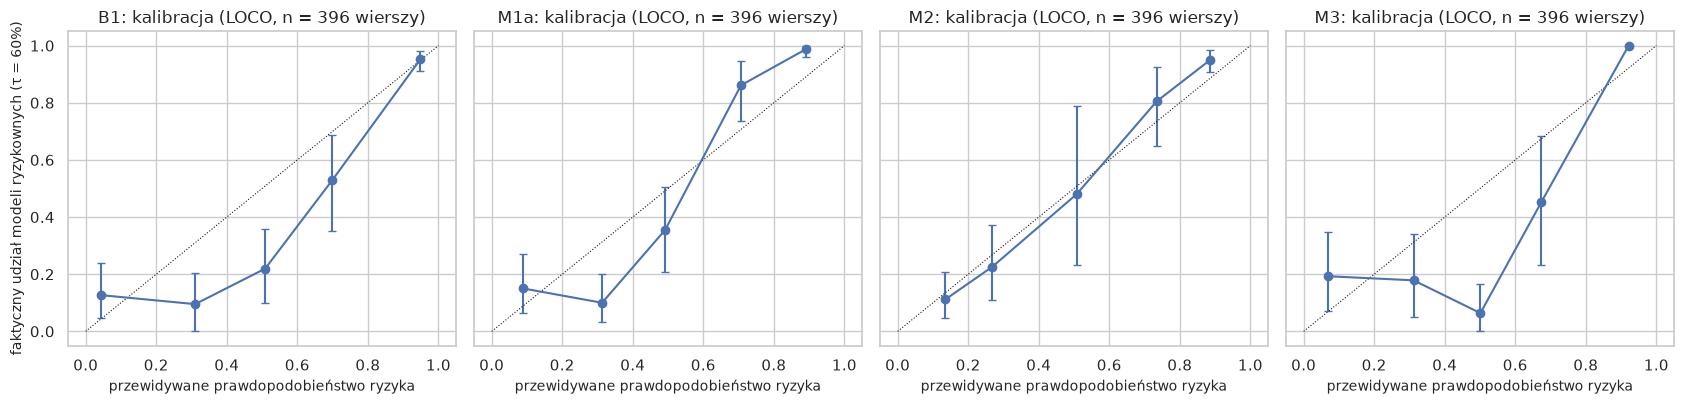

In [26]:
def calib_curve(O, m, bins=5, B=400, seed=3):
    b = np.minimum((O["p__" + m] * bins).astype(int), bins - 1).to_numpy()
    ids_ = O.StyleCode.unique(); rg = np.random.default_rng(seed)
    out = []
    for i in range(bins):
        msk = b == i
        if msk.sum() < 5:
            continue
        v, n = _by_model(O, np.where(msk, O.y, 0), ids_)[0], _by_model(O, msk.astype(float), ids_)[0]
        Wb = rg.multinomial(len(ids_), np.ones(len(ids_)) / len(ids_), size=B)
        den = Wb @ n
        est = np.where(den > 0, (Wb @ v) / np.where(den > 0, den, 1), np.nan)
        out.append((O["p__" + m][msk].mean(), O.y[msk].mean(), *np.nanquantile(est, [.05, .95]), int(msk.sum())))
    return pd.DataFrame(out, columns=["p_śr", "udział", "od", "do", "n"])

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for ax, m in zip(axes, ["B1", "M1a", "M2", "M3"]):
    cc = calib_curve(O, m)
    ax.errorbar(cc.p_śr, cc.udział, yerr=[cc.udział - cc.od, cc.do - cc.udział], fmt="o-", capsize=3)
    ax.plot([0, 1], [0, 1], "k:", lw=0.8)
    ax.set_title(f"{m}: kalibracja (LOCO, n = {len(O)} wierszy)"); ax.set_xlabel("przewidywane prawdopodobieństwo ryzyka")
axes[0].set_ylabel("faktyczny udział modeli ryzykownych (τ = 60%)")
plt.tight_layout(); plt.show()

### Sprawdzenia uzupełniające do Fazy 6

**Po co:** dwa wyniki z tabel wyżej wymagają sprawdzenia, zanim je zinterpretuję: (1) współczynnik cechy `avail_core` wyszedł dokładnie 0, a ΔBrier w teście H4 dokładnie 0: to wygląda na cechę bez zmienności, a nie na „brak efektu”; (2) metoda główna M1a jest **gorsza** od baseline'u B1, a M2 ma tylko minimalnie niższy Brier niż B1; test H3 porównywał M2 tylko z M1a, więc brakuje porównania M2 z B1. Pokazuję, jak zmienia się `avail_core` w danych i dopisuję brakujące pary (te same modele, ten sam bootstrap po modelach).

In [27]:
print("avail_core (udział SKU w rozmiarach M, L i ONE ze stanem > 0 w sieci) w tabeli modelowej D, wg tygodnia decyzji:")
display(D.groupby("k").avail_core.agg(min="min", średnia="mean", max="max", wiersze_poniżej_1=lambda s: int((s < 1).sum())).round(3).T)
a55 = ms[ms.age_d <= 55].groupby("StyleCode").avail_core.min()
print("Najniższa dostępność rdzenia (M, L, ONE) w oknie dni 0–55, na model: rozkład i liczba modeli poniżej 1,0 / 0,9 (wszystkie 96 modeli w serii):")
display(a55.describe().round(3).to_frame("avail_core_min").T)
print("modeli z min < 1,0:", int((a55 < 1).sum()), "| z min < 0,9:", int((a55 < 0.9).sum()), "| z min < 0,8:", int((a55 < 0.8).sum()))

extra = [("M2", "B1", "M2 vs ekstrapolacja (brakująca para do H3)"), ("M2", "B2", "M2 vs B2"), ("M2 + Platt", "B1", "M2 z kalibracją Platta vs B1"),
         ("M1r", "B1", "regresja ciągła vs B1"), ("M3", "M2", "krzywa vs gradientowy")]
rows = []
for a, b, note in extra:
    d1, c1 = boot_diff(O, sq_err(O, a), sq_err(O, b), BS)
    d2, c2 = boot_diff(O, log_loss_rows(O, a), log_loss_rows(O, b), BS)
    rows.append({"porównanie (A − B)": f"{a} − {b}", "opis": note, "ΔBrier": d1, "90% od": c1[0], "90% do": c1[1], "Δlog loss": d2, "ll 90% od": c2[0], "ll 90% do": c2[1]})
display(pd.DataFrame(rows).set_index("porównanie (A − B)").round(4))

# gdzie M1a przegrywa z B1: różnica Brier wg tygodnia decyzji (ten sam wiersz = ta sama decyzja)
dk = O.assign(d_b1=sq_err(O, "B1"), d_m1=sq_err(O, "M1a"), d_m2=sq_err(O, "M2")).groupby("k")[["d_b1", "d_m1", "d_m2"]].mean().round(3)
dk.columns = ["Brier B1", "Brier M1a", "Brier M2"]
display(dk.T)

avail_core (udział SKU w rozmiarach M, L i ONE ze stanem > 0 w sieci) w tabeli modelowej D, wg tygodnia decyzji:


k,2,3,4,5,6,7
min,1.000,1.000,1.000,1.000,1.000,1.000
średnia,1.000,1.000,1.000,1.000,1.000,1.000
max,1.000,1.000,1.000,1.000,1.000,1.000
wiersze_poniżej_1,0.000,0.000,0.000,0.000,0.000,0.000


Najniższa dostępność rdzenia (M, L, ONE) w oknie dni 0–55, na model: rozkład i liczba modeli poniżej 1,0 / 0,9 (wszystkie 96 modeli w serii):


,count,mean,std,min,25%,50%,75%,max
avail_core_min,96.000,1.000,0.000,1.000,1.000,1.000,1.000,1.000


modeli z min < 1,0: 0 | z min < 0,9: 0 | z min < 0,8: 0


,opis,ΔBrier,90% od,90% do,Δlog loss,ll 90% od,ll 90% do
porównanie (A − B),,,,,,,
M2 − B1,M2 vs ekstrapolacja (brakująca para do H3),-0.005,-0.022,0.013,-0.026,-0.104,0.043
M2 − B2,M2 vs B2,-0.009,-0.031,0.013,-0.052,-0.147,0.039
M2 + Platt − B1,M2 z kalibracją Platta vs B1,-0.007,-0.023,0.010,-0.036,-0.111,0.030
M1r − B1,regresja ciągła vs B1,0.007,-0.001,0.015,-0.005,-0.048,0.037
M3 − M2,krzywa vs gradientowy,0.030,0.007,0.055,0.086,0.002,0.178


k,2,3,4,5,6,7
Brier B1,0.248,0.182,0.148,0.089,0.025,0.015
Brier M1a,0.214,0.178,0.162,0.105,0.072,0.069
Brier M2,0.208,0.147,0.114,0.103,0.053,0.051


## Faza 7 — Kalibracja, decyzja i stabilność

**Po co:** prognoza prawdopodobieństwa to jeszcze nie decyzja. Tu sprawdzam: (1) jak koszt zależy od progu flagowania i czy wybrany na walidacji próg ma sens; (2) ile kosztują polityki i reguły w każdym tygodniu decyzji; (3) jak wynik zmienia się z progiem sell-through (50/60/70%) i z założeniami kosztowymi; (4) czy wynik jest stabilny między kolekcjami i kategoriami; (5) które modele metoda myli i dlaczego; (6) czy wynik nie zależy od wykluczenia sześciu modeli przecenionych w 7. tygodniu; (7) czy w cechach nie ma przecieku informacji z przyszłości.

**Dodatkowa reguła „kosztowa” (EV):** zamiast progu na prawdopodobieństwie używam prognozy ciągłej z M1r (średnia `μ` i odchylenie `σ` sell-through w dniu 55) i liczę **oczekiwany koszt** obu decyzji dla każdego modelu: oczekiwany niedobór `E[max(0, τ − ST₅₅)]·dostępne_d` (wzór dla rozkładu normalnego), koszt przeoczenia z macierzy 1.4, a koszt flagi z przewidywanej sprzedaży do dnia 55. Flaguję, gdy `K_flag + (1 − ε)·K_miss < K_miss`. Zaleta: reguła sama uwzględnia, że flaga jest tym tańsza, im mniej sprzedaży zostało do końca okna, i nie wymaga progu dobranego na danych. Wada: zakłada poprawność rozkładu normalnego i dodatkowych przybliżeń (np. dostępne w dniu 55 ≈ dostępne w dniu decyzji).

In [28]:
MAIN = "M1a"   # metoda główna wskazana z góry w fazie 6

def ridge_mu_sd(tr, te, feats=FE_M1, alpha=3.0):
    m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(tr[feats], tr.st55)
    res = (tr.st55 - m.predict(tr[feats])).to_numpy() * np.sqrt(len(tr) / (len(tr) - len(feats) - 1))
    return m.predict(te[feats]), _sigma(res, tr.k.to_numpy(), te.k.to_numpy())

def ev_flag(te, mu, sd, tau, delta=None, d_clear=None, eps=None, hold=None):
    """Flaguj, gdy oczekiwany koszt z flagą < oczekiwany koszt bez flagi (rozkład normalny sell-through w dniu 55)."""
    delta = COST["delta"] if delta is None else delta
    d_clear = COST["delta_clear"] if d_clear is None else d_clear
    eps = EPS if eps is None else eps
    hold = COST["hold_m"] if hold is None else hold
    z = (tau - mu) / sd
    exp_short = sd * (norm.pdf(z) + z * norm.cdf(z))                       # E[max(0, tau - ST55)]
    k_miss = exp_short * te.supply_d.to_numpy() * (d_clear * te.p.to_numpy() + hold * COST["hold_months"] * te.c.to_numpy())
    k_flag = delta * te.p.to_numpy() * np.maximum(mu - te.st_d.to_numpy(), 0) * te.supply_d.to_numpy()
    return k_flag + (1 - eps) * k_miss < k_miss

# dodaję do tabeli out-of-fold prognozę ciągłą z M1r (uczoną tylko na kolekcjach treningowych danego foldu)
O["mu_r"], O["sd_r"] = np.nan, np.nan
for c in COLLS:
    tr_, te_ = D[D.Collection != c], D[D.Collection == c]
    assert set(tr_.StyleCode).isdisjoint(te_.StyleCode)      # ten sam model nigdy w treningu i teście
    mu_, sd_ = ridge_mu_sd(tr_, te_)
    ix = O.index[O.Collection == c]   # kolejność wierszy w O dla kolekcji = kolejność wierszy te_
    O.loc[ix, "mu_r"] = mu_
    O.loc[ix, "sd_r"] = sd_
O["flag__EV"] = ev_flag(O, O.mu_r.to_numpy(), O.sd_r.to_numpy(), TAU)

print("Każdy model należy do jednej kolekcji:", bool((D.groupby("StyleCode").Collection.nunique() == 1).all()))

Każdy model należy do jednej kolekcji: True


### 7.1 Koszt decyzji w zależności od progu

**Po co:** zobaczyć, czy istnieje próg prawdopodobieństwa, przy którym flagowanie się opłaca, i jak bardzo zależy to od tygodnia decyzji. Krzywe liczone na zbiorczych predykcjach out-of-fold są tylko ilustracją (progu do oceny nie wybieram z nich, bo to byłby wybór na danych testowych; próg oceniany w tabelach niżej pochodzi z wewnętrznej walidacji). Poziome linie to koszty polityk „nie flaguj nigdy” i „flaguj zawsze” w tym tygodniu. Koszt to średnia na model w PLN netto.

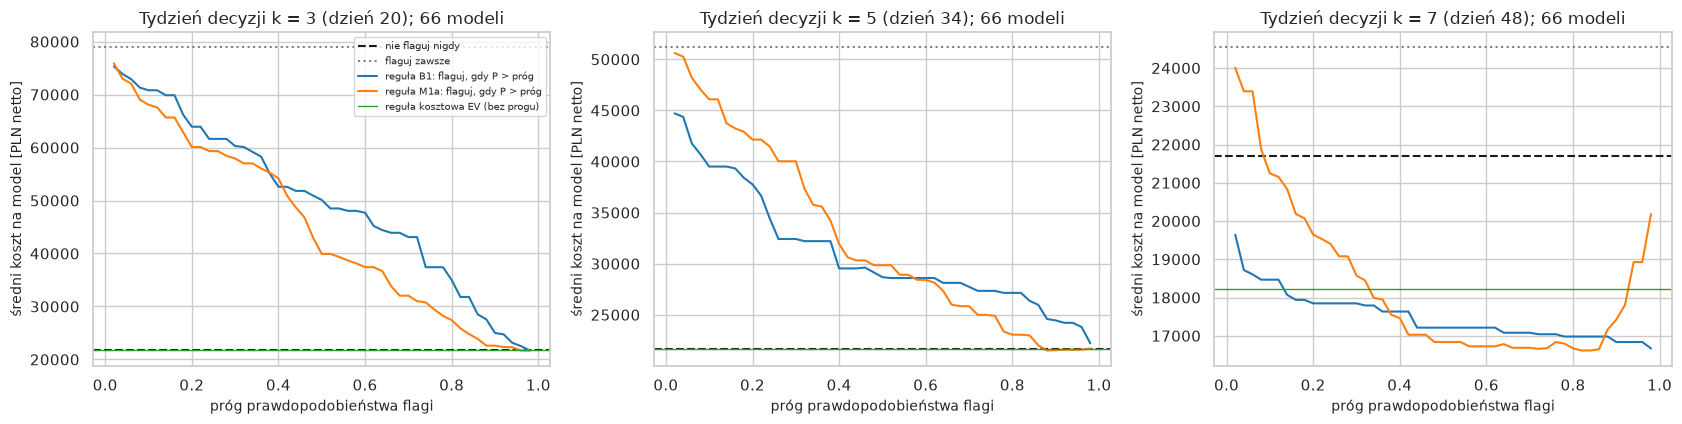

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
thr_grid = np.round(np.arange(0.02, 1.0, 0.02), 2)
for ax, k_ in zip(axes, [3, 5, 7]):
    sub = O[O.k == k_]
    ct = cost_table(sub, TAU)
    ax.axhline(ct.c_no.mean(), color="k", ls="--", label="nie flaguj nigdy")
    ax.axhline(ct.c_flag.mean(), color="gray", ls=":", label="flaguj zawsze")
    for m, col in [("B1", "tab:blue"), (MAIN, "tab:orange")]:
        ax.plot(thr_grid, [np.where(sub["p__" + m] > t, ct.c_flag, ct.c_no).mean() for t in thr_grid], color=col, label=f"reguła {m}: flaguj, gdy P > próg")
    ax.axhline(np.where(sub.flag__EV, ct.c_flag, ct.c_no).mean(), color="tab:green", lw=1, label="reguła kosztowa EV (bez progu)")
    ax.set_title(f"Tydzień decyzji k = {k_} (dzień {7 * k_ - 1}); {sub.StyleCode.nunique()} modeli")
    ax.set_xlabel("próg prawdopodobieństwa flagi"); ax.set_ylabel("średni koszt na model [PLN netto]")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 7.2 Koszt polityk i reguł w każdym tygodniu decyzji (τ = 60%, koszty bazowe)

**Po co:** odpowiedź na pytanie zleceniodawcy „ile to kosztuje i czy lepiej niż dziś”. Próg każdej reguły wybrany jest wyłącznie na kolekcjach treningowych (wewnętrzny LOCO) albo wynika z kosztów (teoretyczny P*). Przedziały: bootstrap po modelach (90%) w obrębie danego tygodnia. „Oszczędność” = koszt polityki „nie flaguj nigdy” minus koszt reguły, w PLN na model; dodatnia oznacza, że reguła jest tańsza niż brak wczesnego działania.

In [30]:
def policy_table(O, tau, ks=None, methods=("B1", MAIN), **kw):
    rows = []
    for k_ in (sorted(O.k.unique()) if ks is None else ks):
        sub = O[O.k == k_].reset_index(drop=True)
        bs = boot_setup(sub, B=800, seed=SEED + int(k_))
        ct = cost_table(sub, tau, **kw)
        never = ct.c_no.to_numpy()
        pol = {"nie flaguj nigdy": never, "flaguj zawsze": ct.c_flag.to_numpy(),
               "praktyka robocza": policy_cost(sub, tau, (sub.st_d < tau * (sub.d + 1) / 56).to_numpy(), **kw)}
        for m in methods:
            pol[f"{m}, próg z walidacji"] = np.where(sub["p__" + m] > sub["thr__" + m], ct.c_flag, ct.c_no)
            pol[f"{m}, próg teoretyczny"] = np.where(sub["p__" + m] > sub["thr_theory"], ct.c_flag, ct.c_no)
        pol["reguła kosztowa EV"] = np.where(sub.flag__EV, ct.c_flag, ct.c_no)
        for name, v in pol.items():
            est, ci = boot_mean(sub, v, bs)
            sav, sci = boot_diff(sub, never, v, bs)
            rows.append({"tydzień k": k_, "polityka / reguła": name, "koszt/model": est, "90% od": ci[0], "90% do": ci[1], "oszczędność vs nie flaguj": sav, "osz. od": sci[0], "osz. do": sci[1],
                         "flagowane modele [%]": 100 * np.mean(np.where(v == never, 0, 1)) if name != "nie flaguj nigdy" else 0.0})
    return pd.DataFrame(rows)

pt = policy_table(O, TAU)
display(pt[pt["tydzień k"].isin([3, 5, 7])].round(0).set_index(["tydzień k", "polityka / reguła"]))
sav_all = pt.pivot(index="polityka / reguła", columns="tydzień k", values="oszczędność vs nie flaguj").round(0)
print("Oszczędność względem „nie flaguj nigdy” [PLN na model], wszystkie tygodnie:")
display(sav_all)

koszt/model     90% od     90% do  oszczędność vs nie flaguj     osz. od     osz. do  flagowane modele [%]
tydzień k polityka / reguła                                                                                                                
3         nie flaguj nigdy        21,692.000 13,642.000 30,423.000                      0.000       0.000       0.000                 0.000
          flaguj zawsze           78,889.000 68,024.000 90,547.000                -57,197.000 -65,893.000 -48,433.000               100.000
          praktyka robocza        53,196.000 40,648.000 67,084.000                -31,505.000 -40,499.000 -23,245.000                61.000
          B1, próg z walidacji    22,786.000 13,946.000 32,442.000                 -1,094.000  -2,215.000     -86.000                 6.000
          B1, próg teoretyczny    21,692.000 13,642.000 30,423.000                      0.000       0.000       0.000                 0.000
          M1a, próg z walidacji   21,692.000 13,642.000 30,423.000                      0.000       0.000       0.000                 0.000
          M1a, próg teoretyczny   21,692.000 13,642.000 30,423.000                      0.000       0.000       0.000                 0.000
          reguła kosztowa EV      21,692.000 13,642.000 30,423.000                      0.000       0.000       0.000                 0.000
5         nie flaguj nigdy        21,692.000 13,790.000 30,734.000                      0.000       0.000       0.000                 0.000
          flaguj zawsze           51,157.000 42,807.000 60,109.000                -29,465.000 -36,323.000 -23,389.000               100.000
          praktyka robocza        33,243.000 23,779.000 43,082.000                -11,551.000 -17,982.000  -6,303.000                47.000
          B1, próg z walidacji    23,895.000 16,003.000 32,753.000                 -2,203.000  -5,017.000      -4.000                24.000
          B1, próg teoretyczny    22,206.000 14,475.000 30,619.000                   -515.000  -1,929.000     850.000                20.000
          M1a, próg z walidacji   21,705.000 13,991.000 30,285.000                    -13.000  -1,458.000   1,402.000                15.000
          M1a, próg teoretyczny   21,692.000 13,790.000 30,734.000                      0.000       0.000       0.000                 0.000
          reguła kosztowa EV      21,692.000 13,790.000 30,734.000                      0.000       0.000       0.000                 0.000
7         nie flaguj nigdy        21,692.000 13,532.000 31,097.000                      0.000       0.000       0.000                 0.000
          flaguj zawsze           24,536.000 19,751.000 29,903.000                 -2,845.000  -6,958.000   1,812.000               100.000
          praktyka robocza        17,476.000 11,963.000 23,633.000                  4,216.000   1,328.000   7,694.000                45.000
          B1, próg z walidacji    16,836.000 11,236.000 23,303.000                  4,856.000   2,051.000   8,178.000                41.000
          B1, próg teoretyczny    17,212.000 11,547.000 23,611.000                  4,480.000   1,612.000   7,874.000                47.000
          M1a, próg z walidacji   16,685.000 11,031.000 23,025.000                  5,006.000   2,247.000   8,295.000                33.000
          M1a, próg teoretyczny   16,891.000 11,316.000 23,358.000                  4,801.000   1,997.000   8,178.000                39.000
          reguła kosztowa EV      18,215.000 12,127.000 25,290.000                  3,477.000     949.000   6,483.000                15.000

Oszczędność względem „nie flaguj nigdy” [PLN na model], wszystkie tygodnie:


tydzień k,2,3,4,5,6,7
polityka / reguła,,,,,,
"B1, próg teoretyczny","-1,759.000",0.000,0.000,-515.000,-978.000,"4,480.000"
"B1, próg z walidacji","-5,738.000","-1,094.000",-422.000,"-2,203.000",-709.000,"4,856.000"
"M1a, próg teoretyczny",0.000,0.000,0.000,0.000,787.000,"4,801.000"
"M1a, próg z walidacji",0.000,0.000,0.000,-13.000,"2,633.000","5,006.000"
flaguj zawsze,"-70,481.000","-57,197.000","-42,816.000","-29,465.000","-15,902.000","-2,845.000"
nie flaguj nigdy,0.000,0.000,0.000,0.000,0.000,0.000
praktyka robocza,"-48,527.000","-31,505.000","-19,710.000","-11,551.000","-2,399.000","4,216.000"
reguła kosztowa EV,0.000,0.000,0.000,0.000,"1,442.000","3,477.000"


### 7.3 Wrażliwość: próg sell-through (50/60/70%) i założenia kosztowe

**Po co:** próg 60% i parametry kosztów to założenia, nie dane. Sprawdzam, czy wnioski o jakości prognozy (Brier, AUC) i o opłacalności reguł zmieniają się, gdy próg to 50% lub 70% oraz gdy zmienię po jednym parametrze kosztowym albo zestaw „tanie i skuteczne działanie” (δ = 5%, ε = 75%; to np. ekspozycja lub przesunięcie zapasu zamiast przeceny; **to scenariusz hipotetyczny, bez danych o rzeczywistym koszcie**). Dla każdego progu τ metody są uczone od nowa z etykietą dla tego τ; dla scenariuszy kosztowych predykcje zostają, a progi teoretyczne liczone są z kosztów danego scenariusza na kolekcjach treningowych.

In [31]:
rows = []
O_tau = {TAU: O}
for tau_ in (0.5, 0.7):
    O_tau[tau_] = run_cv({"B0g": m_B0g, "B1": m_B1, MAIN: METH[MAIN]}, tau_)
    for c in COLLS:
        tr_, te_ = D[D.Collection != c], D[D.Collection == c]
        mu_, sd_ = ridge_mu_sd(tr_, te_)
        ix = O_tau[tau_].index[O_tau[tau_].Collection == c]
        O_tau[tau_].loc[ix, "mu_r"], O_tau[tau_].loc[ix, "sd_r"] = mu_, sd_
    O_tau[tau_]["flag__EV"] = ev_flag(O_tau[tau_], O_tau[tau_].mu_r.to_numpy(), O_tau[tau_].sd_r.to_numpy(), tau_)
for tau_, Ot in O_tau.items():
    bs_ = boot_setup(Ot, B=800)
    ct = cost_table(Ot, tau_)
    r = {"τ": tau_, "udział ryzykownych": Ot.y.mean(), "Brier B0g": boot_mean(Ot, sq_err(Ot, "B0g"), bs_)[0]}
    for m in ("B1", MAIN):
        e, ci = boot_mean(Ot, sq_err(Ot, m), bs_)
        r[f"Brier {m}"], r[f"Brier {m} od"], r[f"Brier {m} do"] = e, ci[0], ci[1]
        r[f"AUC {m}"] = roc_auc_score(Ot.y, Ot["p__" + m])
    r["koszt: nie flaguj"] = ct.c_no.mean()
    r["koszt: flaguj zawsze"] = ct.c_flag.mean()
    r[f"koszt: {MAIN} próg teor."] = np.where(Ot["p__" + MAIN] > Ot.thr_theory, ct.c_flag, ct.c_no).mean()
    r[f"koszt: {MAIN} próg walid."] = np.where(Ot["p__" + MAIN] > Ot["thr__" + MAIN], ct.c_flag, ct.c_no).mean()
    r["koszt: EV"] = np.where(Ot.flag__EV, ct.c_flag, ct.c_no).mean()
    rows.append(r)
display(pd.DataFrame(rows).set_index("τ").T.round(3))

scen = {"bazowy (δ 20%, ε 50%, Δ 25 p.p., h 1,5%)": {}, "δ = 10%": dict(delta=0.10), "δ = 30%": dict(delta=0.30), "ε = 25%": dict(eps=0.25), "ε = 75%": dict(eps=0.75),
        "Δ = 15 p.p.": dict(d_clear=0.15), "Δ = 35 p.p.": dict(d_clear=0.35), "h = 3%": dict(hold=0.03), "δ = 5% i ε = 75% (tanie, skuteczne działanie)": dict(delta=0.05, eps=0.75),
        "δ = 5% i ε = 50%": dict(delta=0.05)}
rows = []
for name, kw in scen.items():
    ct = cost_table(O, TAU, **kw)
    cth = np.zeros(len(O))
    for c in COLLS:
        thr_k = theory_threshold(D[D.Collection != c], TAU, **kw)
        ix = np.where(O.Collection == c)[0]
        cth[ix] = np.where(O["p__" + MAIN].to_numpy()[ix] > O.k.iloc[ix].map(thr_k).to_numpy(), ct.c_flag.to_numpy()[ix], ct.c_no.to_numpy()[ix])
    ev = np.where(ev_flag(O, O.mu_r.to_numpy(), O.sd_r.to_numpy(), TAU, **kw), ct.c_flag, ct.c_no)
    rows.append({"scenariusz": name, "nie flaguj": ct.c_no.mean(), "flaguj zawsze": ct.c_flag.mean(), f"{MAIN} (próg teor.)": cth.mean(), "EV": ev.mean(),
                 "oszczędność EV vs nie flaguj [%]": 100 * (1 - ev.mean() / ct.c_no.mean()), f"oszczędność {MAIN} vs nie flaguj [%]": 100 * (1 - cth.mean() / ct.c_no.mean())})
display(pd.DataFrame(rows).set_index("scenariusz").round(1))

τ,0.600,0.500,0.700
udział ryzykownych,0.470,0.288,0.742
Brier B0g,0.293,0.222,0.219
Brier B1,0.118,0.074,0.138
Brier B1 od,0.086,0.054,0.103
Brier B1 do,0.149,0.095,0.173
AUC B1,0.918,0.972,0.882
Brier M1a,0.133,0.064,0.178
Brier M1a od,0.105,0.040,0.138
Brier M1a do,0.166,0.087,0.222
AUC M1a,0.885,0.960,0.738


,nie flaguj,flaguj zawsze,M1a (próg teor.),EV,oszczędność EV vs nie flaguj [%],oszczędność M1a vs nie flaguj [%]
scenariusz,,,,,,
"bazowy (δ 20%, ε 50%, Δ 25 p.p., h 1,5%)","21,691.700","58,142.800","20,760.400","20,872.000",3.800,4.300
δ = 10%,"21,691.700","34,494.300","19,589.000","19,479.800",10.200,9.700
δ = 30%,"21,691.700","81,791.300","21,289.300","21,472.900",1.000,1.900
ε = 25%,"21,691.700","63,565.800","21,613.400","21,658.200",0.200,0.400
ε = 75%,"21,691.700","52,719.900","19,527.900","19,257.100",11.200,10.000
Δ = 15 p.p.,"13,408.300","54,001.100","13,161.500","13,317.500",0.700,1.800
Δ = 35 p.p.,"29,975.100","62,284.500","28,083.600","27,898.800",6.900,6.300
h = 3%,"22,674.800","58,634.400","21,579.700","21,788.500",3.900,4.800
"δ = 5% i ε = 75% (tanie, skuteczne działanie)","21,691.700","17,247.200","12,652.200","11,231.900",48.200,41.700


### 7.4 Stabilność między kolekcjami i kategoriami; analiza błędów

**Po co:** wynik zbiorczy może ukrywać, że metoda działa tylko dla jednej kolekcji lub kategorii (pytanie 4 z przeglądu krytycznego). Pokazuję Brier i koszt per kolekcja testowa i per kategoria oraz listę modeli, które metoda główna myli najmocniej w tygodniu 4 (dzień 27), z cechami, które mogą to tłumaczyć.

In [32]:
fold = O.groupby("Collection").apply(lambda g: pd.Series({
    "modeli": g.StyleCode.nunique(), "udział ryzykownych": g.y.mean(), "Brier B1": (sq_err(g, "B1")).mean(), f"Brier {MAIN}": sq_err(g, MAIN).mean(),
    "Brier B0g": sq_err(g, "B0g").mean(), "AUC B1": roc_auc_score(g.y, g.p__B1), f"AUC {MAIN}": roc_auc_score(g.y, g["p__" + MAIN])}), include_groups=False)
display(fold.round(3))
cat_tab = O.groupby("Category").apply(lambda g: pd.Series({
    "modeli": g.StyleCode.nunique(), "kolekcje": ", ".join(sorted(g.Collection.unique())), "udział ryzykownych": g.y.mean(), "Brier B1": sq_err(g, "B1").mean(), f"Brier {MAIN}": sq_err(g, MAIN).mean()}), include_groups=False)
display(cat_tab)
e4 = O[O.k == 4].assign(blad=lambda d: (d["p__" + MAIN] - d.y).abs())
display(e4.sort_values("blad", ascending=False).head(8)[["StyleCode", "Collection", "Category", "st_d", "pred55", "restock", "st55", "y", "p__B1", "p__" + MAIN, "avail_core"]].round(3))
print("Przy tygodniu 4 metoda główna najmocniej myli się dla modeli: wyżej. Uzupełnienie dostaw po dniu 27 (restock rośnie później) jest nieznane w momencie decyzji.")
late_restock = (D[D.k == 4].set_index("StyleCode").supply55 / D[D.k == 4].set_index("StyleCode").supply_d - 1).rename("przyrost_dostepnych_27_55")
e4 = e4.join(late_restock, on="StyleCode")
print("Korelacja rang: błąd prognozy M1a w tygodniu 4 vs późniejsze uzupełnienia (przyrost dostępnych sztuk od dnia 27 do 55):",
      round(spearmanr(e4.blad, e4.przyrost_dostepnych_27_55)[0], 3), "| modeli z późniejszym uzupełnieniem > 5%:", int((e4.przyrost_dostepnych_27_55 > 0.05).sum()))

,modeli,udział ryzykownych,Brier B1,Brier M1a,Brier B0g,AUC B1,AUC M1a
Collection,,,,,,,
AW25,22.000,0.727,0.124,0.158,0.348,0.902,0.874
SS25,21.000,0.381,0.117,0.115,0.253,0.901,0.875
SS26,23.000,0.304,0.113,0.126,0.276,0.930,0.923


,modeli,kolekcje,udział ryzykownych,Brier B1,Brier M1a
Category,,,,,
Akcesoria,13,"AW25, SS25, SS26",0.538,0.136,0.151
Jeansy,9,"AW25, SS25, SS26",0.444,0.068,0.078
Koszule,9,"AW25, SS25, SS26",0.222,0.139,0.168
Kurtki,7,AW25,0.857,0.047,0.081
Sukienki,11,"SS25, SS26",0.364,0.071,0.082
Swetry,6,AW25,0.667,0.253,0.300
T-shirty,11,"SS25, SS26",0.364,0.138,0.124


,StyleCode,Collection,Category,st_d,pred55,restock,st55,y,p__B1,p__M1a,avail_core
184,M-KNT-102,AW25,Swetry,0.473,1.000,0.000,0.585,1,0.008,0.010,1.000
50,M-TSH-101,SS25,T-shirty,0.531,1.000,0.000,0.590,1,0.007,0.011,1.000
183,M-KNT-101,AW25,Swetry,0.434,0.976,0.000,0.501,1,0.012,0.012,1.000
60,W-SHI-101,SS25,Koszule,0.479,0.990,0.000,0.504,1,0.009,0.022,1.000
306,A-BAG-107,SS26,Akcesoria,0.524,1.000,0.000,0.584,1,0.011,0.027,1.000
172,A-SCF-103,AW25,Akcesoria,0.345,0.713,0.000,0.401,1,0.249,0.155,1.000
310,M-SHI-106,SS26,Koszule,0.264,0.576,0.000,0.655,0,0.553,0.743,1.000
319,W-DRS-113,SS26,Sukienki,0.272,0.581,0.000,0.612,0,0.543,0.634,1.000


Przy tygodniu 4 metoda główna najmocniej myli się dla modeli: wyżej. Uzupełnienie dostaw po dniu 27 (restock rośnie później) jest nieznane w momencie decyzji.
Korelacja rang: błąd prognozy M1a w tygodniu 4 vs późniejsze uzupełnienia (przyrost dostępnych sztuk od dnia 27 do 55): -0.139 | modeli z późniejszym uzupełnieniem > 5%: 15


### 7.5 Wrażliwość na wykluczenie modeli przecenionych w 7. tygodniu oraz test przecieku

**Po co:** (a) sześć modeli z rabatem od dnia 42 wykluczyłem z oceny, bo ich wynik w dniu 55 jest zmieszany z rabatem. Sprawdzam, czy włączenie ich (z obserwowanym, zawyżonym wynikiem) zmienia ocenę metod w momentach, w których ich cechy są jeszcze „czyste” (tygodnie 2–6, dni do 41). (b) Test przecieku: dla losowych wierszy odtwarzam cechy z surowej serii obciętej do dnia decyzji i porównuję z tabelą modelową. Jeśli cechy zależałyby od danych po dniu decyzji, wartości by się różniły.

In [33]:
Dc = D_all[(D_all.k <= 6)].copy()
Dc["cat"] = Dc.Category.map({c: i for i, c in enumerate(CATS)})
Dn = D[D.k <= 6].copy()
res_ = []
for lbl, dd in [("bez cenzurowanych (analiza główna, tygodnie 2–6)", Dn), ("z cenzurowanymi (obserwowany wynik zawyżony przeceną)", Dc)]:
    Ot = run_cv({"B1": m_B1, MAIN: METH[MAIN]}, TAU, data=dd.reset_index(drop=True))
    bs_ = boot_setup(Ot, B=800)
    r = {"zbiór": lbl, "modeli": Ot.StyleCode.nunique(), "udział ryzykownych": Ot.y.mean()}
    for m in ("B1", MAIN):
        e, ci = boot_mean(Ot, sq_err(Ot, m), bs_)
        r[f"Brier {m}"], r[f"{m} 90% od"], r[f"{m} 90% do"] = e, ci[0], ci[1]
    res_.append(r)
display(pd.DataFrame(res_).set_index("zbiór").round(3))

# test przecieku: cechy odtworzone z danych obciętych do dnia decyzji
rg_ = np.random.default_rng(SEED + 5)
chk_rows = D.iloc[rg_.choice(len(D), 8, replace=False)]
diffs = []
for r in chk_rows.itertuples():
    g = ms[(ms.StyleCode == r.StyleCode) & (ms.age_d <= r.d)].set_index("age_d")
    cum_d, cum_p = g.cum.loc[r.d], (g.cum.loc[r.d - 14] if r.d - 14 >= 0 else 0.0)
    st_d_ = g.st.loc[r.d]
    rate_ = (cum_d - cum_p) / 14 / g.supply.loc[r.d]
    pred_ = min(1.0, st_d_ + rate_ * (55 - r.d))
    trend_ = np.log((g.u7.loc[r.d] + 1) / (g.u7.loc[r.d - 7] + 1))
    rest_ = g.supply.loc[r.d] / g.supply.loc[0] - 1
    diffs.append(max(abs(pred_ - r.pred55), abs(trend_ - r.trend), abs(rest_ - r.restock), abs(g.avail_core.loc[r.d] - r.avail_core)))
print("Test przecieku: największa różnica między cechami z tabeli a cechami z danych obciętych do dnia decyzji (8 losowych wierszy):", f"{max(diffs):.2e}")

,modeli,udział ryzykownych,Brier B1,B1 90% od,B1 90% do,Brier M1a,M1a 90% od,M1a 90% do
zbiór,,,,,,,,
"bez cenzurowanych (analiza główna, tygodnie 2–6)",66,0.470,0.138,0.101,0.175,0.152,0.120,0.188
z cenzurowanymi (obserwowany wynik zawyżony przeceną),72,0.486,0.147,0.110,0.190,0.155,0.125,0.189


Test przecieku: największa różnica między cechami z tabeli a cechami z danych obciętych do dnia decyzji (8 losowych wierszy): 0.00e+00


In [34]:
O.to_parquet('ref_O_final.parquet'); tab6.to_csv('ref_tab6.csv'); dt.to_csv('ref_pairs.csv'); D.to_parquet('ref_D.parquet')